# Imports

In [1]:
import numpy as np

import matplotlib
import matplotlib.pyplot as plt
from matplotlib.ticker import ScalarFormatter
import matplotlib.cm as cm
from matplotlib.colors import Normalize
matplotlib.rc_file('C:\\Users\\runner\\matplotlibrc.txt')

import imageio.v2 as imageio
from tqdm import tqdm

import os, sys, subprocess
sys.path.append("D:\\DATA\\ActivePIC")
from pathlib import Path
rsoft_python_paths = [
    r"C:\Synopsys\PhotonicSolutions\2024.09-SP2-3\RSoft\products\most\python",
    r"C:\Synopsys\PhotonicSolutions\2024.09-SP2-3\RSoft\bin",
    r"C:\Synopsys\PhotonicSolutions\2024.09-SP2-3\RSoft\products\python\python3.11\Lib\site-packages"
]
for p in rsoft_python_paths:
    if p not in sys.path:
        sys.path.insert(0, p)
from rstools import RSoftCircuit
import rsoft_lib as rlib

import importlib

# Straight waveguide: 2D convergence test in grid size and grid edge factor

In [43]:
# Define directories and files to work with
working_dir = "D:\\DATA\\ActivePIC\\SingleWaveguideConvergence\\"
save_dir = f"{working_dir}StraightWaveguide_scan_gridSize_gridEdgeFactor\\Volume10_PML5\\"
os.makedirs(save_dir, exist_ok=True)
filename_root = "StraightWaveguide"
filename = f"{filename_root}.ind"

# Define parameter scan
# grid_size_arr = [0.05, 0.06, 0.07, 0.08, 0.09, *np.arange(0.1, 1.1, 0.1)]
grid_size_arr = [0.01, 0.02, 0.03][:1]
grid_edge_arr = np.arange(0.1, 1.0, 0.1)
wav_arr = np.linspace (1.45, 1.65, 5)

for wav in tqdm(wav_arr, desc='Wavelength loop', position=0, leave=False): 
    print(f'Wavelength: {wav} microns')
    wav_str = f"{wav:0.3f}".replace(".", "p")
    for grid_size in tqdm(grid_size_arr[::-1], desc='Grid size loop', position=0, leave=False):
        grid_size_str = f"{grid_size:0.3f}".replace(".", "p")
        for grid_edge in tqdm(grid_edge_arr[::-1], desc='Grid edge loop', position=0, leave=False):  
            grid_edge_str = f"{grid_edge:0.3f}".replace(".", "p")

            c = RSoftCircuit()
            c.read(working_dir+filename)
            c.set_symbol("free_space_wavelength", wav)
            c.set_symbol("Contrast", 1.02)
            c.set_symbol("Grid_x", grid_size)
            c.set_symbol("Grid_y", grid_size)
            c.set_symbol("Grid_z", grid_size)
            c.set_symbol("Grid_Edge", grid_edge)
            # c.set_symbol("PML_width", 10)
            # c.set_symbol("Volume_transverse", 25)
            c.set_symbol("PML_width", 5)
            c.set_symbol("Volume_transverse", 10)
            c.write(working_dir+filename)
            
            command = ["femsim", "-min", filename, "mode_method=1", "mode_set=1", "idbpm_convergence_warning=0",
                    f"prefix={save_dir}/{filename_root}_Wav{wav_str}_GridSize{grid_size_str}_GridEdge{grid_edge_str}", "wait=0"]

            print(f'Wavelength written: {rsoft_lib.read_symbol(working_dir+filename, "free_space_wavelength")}')
            print(f'Grid size written: {rsoft_lib.read_symbol(working_dir+filename, "Grid_x")}')
            print(f'Grid edge factor written: {rsoft_lib.read_symbol(working_dir+filename, "Grid_Edge")}')
            
            # Run the command
            result = subprocess.run(command, cwd=working_dir, capture_output=True, text=True)

            metadata_name = f'{save_dir}{filename_root}_Wav{wav_str}_GridSize{grid_size_str}_GridEdge{grid_edge_str}.json'
            symbols = rsoft_lib.export_symbols(working_dir+filename, metadata_name)

            filename_nef = f'{save_dir}/{filename_root}_Wav{wav_str}_GridSize{grid_size_str}_GridEdge{grid_edge_str}.nef'         
            sim = np.genfromtxt(filename_nef)
            neff = sim[1]
            print(f"n_eff: {neff}")

np.save(f"{save_dir}{filename_root}_Wav.npy", wav_arr)
grid_size_arr_old = np.load(f"{save_dir}{filename_root}_GridSize.npy")
np.save(f"{save_dir}{filename_root}_GridSize.npy", np.hstack([grid_size_arr, grid_size_arr_old]))
grid_edge_arr_old = np.load(f"{save_dir}{filename_root}_GridEdge.npy")
np.save(f"{save_dir}{filename_root}_GridEdge.npy", np.hstack([grid_edge_arr_old, grid_edge_arr]))

Wavelength loop:   0%|          | 0/5 [00:00<?, ?it/s]

Wavelength: 1.45 microns


Grid edge loop:   0%|          | 0/9 [00:00<?, ?it/s]

Wavelength written: 1.45
Grid size written: 0.01
Grid edge factor written: 0.9


FileNotFoundError: D:\DATA\ActivePIC\SingleWaveguideConvergence\StraightWaveguide_scan_gridSize_gridEdgeFactor\Volume10_PML5\/StraightWaveguide_Wav1p450_GridSize0p010_GridEdge0p900.nef not found.

Plot GIF showing convergence of $n_{\text{eff}}$

In [41]:
working_dir = "D:\\DATA\\ActivePIC\\SingleWaveguideConvergence\\"
save_dir = f"{working_dir}StraightWaveguide_scan_gridSize_gridEdgeFactor\\"
filename_root = "StraightWaveguide"

gif_path = os.path.join(save_dir, f"{filename_root}_neff_convergence.gif")
frame_dir = os.path.join(save_dir, "gif_frames")
os.makedirs(frame_dir, exist_ok=True)

wav_arr = np.load(f"{save_dir}{filename_root}_Wav.npy")[:1]
# grid_size_arr = np.load(f"{save_dir}{filename_root}_GridSize.npy")
grid_size_arr = [0.02, 0.03, 0.04, 0.05, 0.06, 0.07, 0.08, 0.09, *np.arange(0.1, 1.1, 0.1)]
grid_edge_arr = np.load(f"{save_dir}{filename_root}_GridEdge.npy")

n_wav, n_size, n_edge = len(wav_arr), len(grid_size_arr), len(grid_edge_arr)

neff_cube = np.full((n_wav, n_size, n_edge), np.nan)

np.save(f"{save_dir}{filename_root}_neff.npy", neff_cube)

for iw, wav in enumerate(wav_arr):
    wav_str = f"{wav:0.3f}".replace(".", "p")
    for isz, grid_size in enumerate(grid_size_arr):
        grid_size_str = f"{grid_size:0.3f}".replace(".", "p")
        for ied, grid_edge in enumerate(grid_edge_arr):
            grid_edge_str = f"{grid_edge:0.3f}".replace(".", "p")
            if grid_size == 0.02:
                fn = (f'{save_dir}Volume10_PML5\\{filename_root}_Wav{wav_str}_GridSize{grid_size_str}'
                  f'_GridEdge{grid_edge_str}.nef')
            else:
                fn = (f'{save_dir}{filename_root}_Wav{wav_str}_GridSize{grid_size_str}'
                                  f'_GridEdge{grid_edge_str}.nef')
            try:
                sim = np.genfromtxt(fn)
                neff_cube[iw, isz, ied] = sim[1]
            except (FileNotFoundError, IndexError, OSError):
                pass  # left as NaN

n_missing = np.isnan(neff_cube).sum()
if n_missing:
    print(f"Warning: {n_missing} of {neff_cube.size} (wav, grid_size, grid_edge) "
          f"combinations had no readable .nef file and will show as blank cells.")

size_labels = [f"{v:.3f}" for v in grid_size_arr]
edge_labels = [f"{v:.2f}" for v in grid_edge_arr]

frame_paths = []
cmap = plt.get_cmap("viridis").copy()
cmap.set_bad(color="lightgray")  # missing (.nef not found) cells

for iw, wav in enumerate(wav_arr):
    fig, ax = plt.subplots(figsize=(9,9.5))

    vmin = np.nanmax(neff_cube[iw]) - 5e-6 #np.percentile(neff_cube[iw], 99)
    vmax = np.nanmax(neff_cube[iw])

    im = ax.imshow(
        neff_cube[iw],           # shape (n_size, n_edge)
        origin="lower",
        aspect="equal",          # every cell literally square
        vmin=vmin, vmax=vmax,
        cmap=cmap,
        interpolation="nearest",
    )

    ax.set_xticks(range(n_edge))
    ax.set_xticklabels(edge_labels, rotation=45, ha="right")
    ax.set_yticks(range(n_size))
    ax.set_yticklabels(size_labels)

    ax.set_xlabel("Grid Edge factor")
    ax.set_ylabel("Grid Size (\u03bcm)")
    ax.set_title(f"\u03bb = {wav:.3f} \u03bcm")

    cbar = fig.colorbar(im, ax=ax)
    cbar.set_label(r"$n_{\mathrm{eff}}$", rotation=270, labelpad=20)

    fmt = ScalarFormatter(useOffset=False)
    fmt.set_scientific(False)
    cbar.ax.yaxis.set_major_formatter(fmt)
 
    frame_path = os.path.join(frame_dir, f"frame_{iw:03d}.png")
    fig.savefig(frame_path, dpi=120)   # no tight_layout/bbox_inches="tight" -- fixed axes instead
    plt.close(fig)
    frame_paths.append(frame_path)
 
# --------------------------------------------------------------------- #
# Assemble into a GIF
# --------------------------------------------------------------------- #
frames = [imageio.imread(p) for p in frame_paths]
 
# Safety net: even with fixed figsize/dpi, matplotlib can occasionally
# round to a slightly different pixel count between frames. If that
# happens, crop every frame down to the smallest common height/width
# rather than letting mimsave fail outright.
shapes = {f.shape for f in frames}
if len(shapes) > 1:
    min_h = min(f.shape[0] for f in frames)
    min_w = min(f.shape[1] for f in frames)
    print(f"Warning: frames had inconsistent shapes {shapes}; "
            f"cropping all frames to ({min_h}, {min_w}).")
    frames = [f[:min_h, :min_w] for f in frames]

imageio.mimsave(gif_path, frames, fps=0.5, loop=0)  # 1 s/frame, loop forever

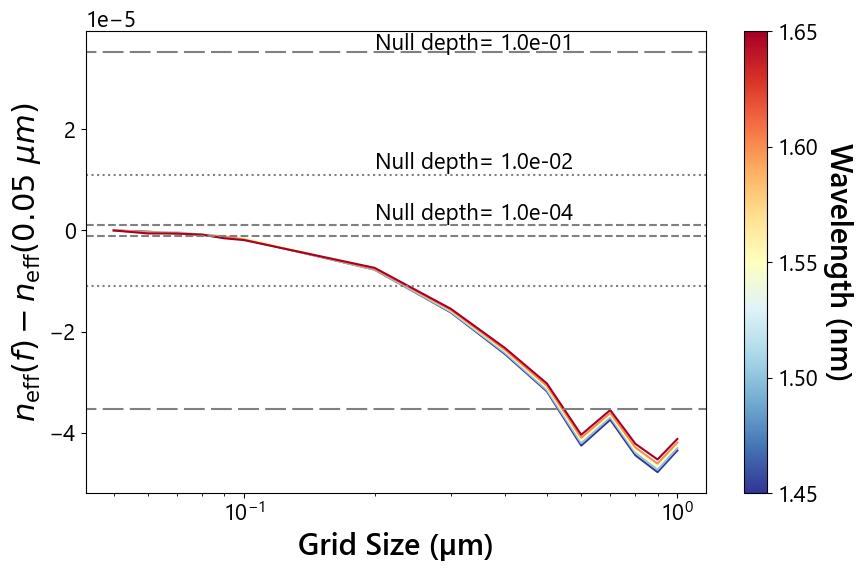

In [118]:
ind_grid_size = int(np.argwhere(grid_size_arr == 0.1))
ind_grid_edge = int(np.argwhere(grid_edge_arr == 0.1))

cmap = plt.get_cmap('RdYlBu_r')
norm = Normalize(vmin=min(wav_arr), vmax=max(wav_arr))
 
fig, ax = plt.subplots(figsize=(10, 6))
 
y = neff_cube[:, :, ind_grid_edge] - neff_cube[:, 0, ind_grid_edge][:, None]
 
for i, w in enumerate(wav_arr):
    ax.semilogx(grid_size_arr, y[i], color=cmap(norm(w)))
 
ntable = np.loadtxt(f'D:\\DATA\\SURF_2026\\ConvergenceTest\\Neff_tolerance.txt', delimiter=',', skiprows=1)
 
ax.axhline(ntable[0, 1], linestyle=(5, (10, 3)), color="grey")
ax.axhline(ntable[1, 1], linestyle="dotted", color="grey")
ax.axhline(ntable[3, 1], linestyle="dashed", color="grey")
 
ax.axhline(-ntable[0, 1], linestyle=(5, (10, 3)), color="grey")
ax.axhline(-ntable[1, 1], linestyle="dotted", color="grey")
ax.axhline(-ntable[3, 1], linestyle="dashed", color="grey")
 
ax.text(0.2, ntable[0, 1]*1.01, f"Null depth= {ntable[0, 0]:0.1e}", fontsize=16)
ax.text(0.2, ntable[1, 1]*1.1, f"Null depth= {ntable[1, 0]:0.1e}", fontsize=16)
ax.text(0.2, ntable[3, 1]*1.9, f"Null depth= {ntable[3, 0]:0.1e}", fontsize=16)
 
ax.set_xlabel("Grid Size (µm)")
ax.set_ylabel(r"$n_{\rm eff}(f) - n_{\rm eff}(0.05\ µm)$")
 
sm = cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])
cbar = fig.colorbar(sm, ax=ax)
cbar.set_label('Wavelength (nm)', rotation=270, labelpad=25)
cbar.set_ticks(wav_arr)
 
plt.show()

Convergence test suggests grid size is the dominant factor, converging at $\leq 0.1$ µm. Grid edge factor is irrelevant in this regime, we will default to 0.1 just to be safe for now.

Test repeatability of FemSIM calculation

In [32]:
# Define directories and files to work with
working_dir = "D:\\DATA\\ActivePIC\\SingleWaveguideConvergence\\"
save_dir = f"{working_dir}StraightWaveguide_repeatability\\"
os.makedirs(save_dir, exist_ok=True)
filename_root = "StraightWaveguide"
filename = f"{filename_root}.ind"

# Define parameter scan
grid_size = 0.1
grid_edge = 0.5
wav = 1.55

neffs = []

for trial in tqdm(np.arange(100), desc='Trial loop', position=0, leave=False):  
    c = RSoftCircuit()
    c.read(working_dir+filename)
    c.set_symbol("free_space_wavelength", wav)
    c.set_symbol("Contrast", 1.02)
    c.set_symbol("Grid_x", grid_size)
    c.set_symbol("Grid_y", grid_size)
    c.set_symbol("Grid_z", grid_size)
    c.set_symbol("Grid_Edge", grid_edge)
    c.set_symbol("PML_width", 10)
    c.set_symbol("Volume_transverse", 25)
    c.write(working_dir+filename)
    
    command = ["femsim", "-min", filename, "mode_method=1", "mode_set=1", "idbpm_convergence_warning=0",
            f"prefix={save_dir}{filename_root}_repeatability", "wait=0"]

    print(f'Wavelength written: {rsoft_lib.read_symbol(working_dir+filename, "free_space_wavelength")}')
    print(f'Grid size written: {rsoft_lib.read_symbol(working_dir+filename, "Grid_x")}')
    print(f'Grid edge factor written: {rsoft_lib.read_symbol(working_dir+filename, "Grid_Edge")}')
    
    # Run the command
    result = subprocess.run(command, cwd=working_dir, capture_output=True, text=True)

    metadata_name = f'{save_dir}{filename_root}_repeatability.json'
    symbols = rsoft_lib.export_symbols(working_dir+filename, metadata_name)

    filename_nef = f'{save_dir}/{filename_root}_repeatability.nef'         
    sim = np.genfromtxt(filename_nef)
    neffs.append(sim[1])


Trial loop:   0%|          | 0/100 [00:00<?, ?it/s]

Wavelength written: 1.55
Grid size written: 0.1
Grid edge factor written: 0.5


Trial loop:   1%|          | 1/100 [02:06<3:28:46, 126.53s/it]

Wavelength written: 1.55
Grid size written: 0.1
Grid edge factor written: 0.5


Trial loop:   2%|▏         | 2/100 [04:15<3:29:28, 128.25s/it]

Wavelength written: 1.55
Grid size written: 0.1
Grid edge factor written: 0.5


... (111 outputs left out)

Wavelength written: 1.55
Grid size written: 0.1
Grid edge factor written: 0.5


Trial loop:  59%|█████▉    | 59/100 [2:11:03<1:36:34, 141.32s/it]

Wavelength written: 1.55
Grid size written: 0.1
Grid edge factor written: 0.5


KeyboardInterrupt: 

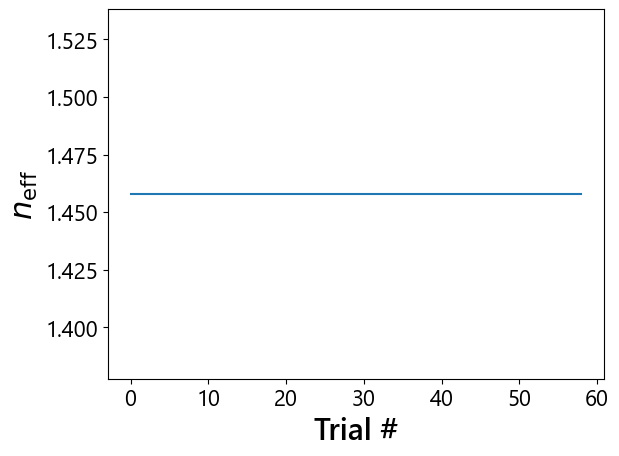

In [33]:
plt.figure()
plt.plot(neffs)
plt.xlabel('Trial #')
plt.ylabel('$n_{\mathrm{eff}}$')
plt.show()

# Straight waveguide:boundary conditions convergence test

Parameters relevant to boundary conditions in FemSIM:
- PML width
- Number of points in PML (determined by global gridding)
- Symmetric, antisymmetric, or None (I set to None, so calculates for the full volume)

In [32]:
# Define directories and files to work with
working_dir = "D:\\DATA\\ActivePIC\\SingleWaveguideConvergence\\"
save_dir = f"{working_dir}StraightWaveguide_scan_PMLwidth_VolumeXY_fine\\"
os.makedirs(save_dir, exist_ok=True)
filename_root = "StraightWaveguide"
filename = f"{filename_root}.ind"

# Define parameter scan
PML_arr = np.arange(0, 2.1, 0.25)
volume_arr = np.arange(2, 8.1, 1)
wav_arr = np.linspace (1.45, 1.65, 5)
grid_size, grid_edge = 0.1, 0.1

for wav in tqdm(wav_arr, desc='Wavelength loop', position=0, leave=False): 
    print(f'Wavelength: {wav} microns')
    wav_str = f"{wav:0.3f}".replace(".", "p")
    for PML in tqdm(PML_arr, desc='PML width loop', position=0, leave=False):
        PML_str = f"{PML:0.3f}".replace(".", "p")
        for volume in tqdm(volume_arr, desc='Volume loop', position=0, leave=False):  
            volume_str = f"{volume:0.3f}".replace(".", "p")

            c = RSoftCircuit()
            c.read(working_dir+filename)
            c.set_symbol("free_space_wavelength", wav)
            c.set_symbol("Contrast", 1.02)
            c.set_symbol("Grid_x", grid_size)
            c.set_symbol("Grid_y", grid_size)
            c.set_symbol("Grid_z", grid_size)
            c.set_symbol("Grid_Edge", grid_edge)

            c.set_symbol("PML_width", PML)
            c.set_symbol("Volume_transverse", volume)


            c.write(working_dir+filename)
            
            command = ["femsim", "-min", filename, "mode_method=1", "mode_set=1", "idbpm_convergence_warning=0",
                    f"prefix={save_dir}/{filename_root}_Wav{wav_str}_PML{PML_str}_Volume{volume_str}", "wait=0"]

            print(f'Wavelength written: {rsoft_lib.read_symbol(working_dir+filename, "free_space_wavelength")}')
            print(f'PML width written: {rsoft_lib.read_symbol(working_dir+filename, "PML_width")}')
            print(f'Volume written: {rsoft_lib.read_symbol(working_dir+filename, "Volume_transverse")}')
            
            # Run the command
            result = subprocess.run(command, cwd=working_dir, capture_output=True, text=True)

            metadata_name = f'{save_dir}{filename_root}_Wav{wav_str}_PML{PML_str}_Volume{volume_str}.json'
            symbols = rsoft_lib.export_symbols(working_dir+filename, metadata_name)

            filename_nef = f'{save_dir}/{filename_root}_Wav{wav_str}_PML{PML_str}_Volume{volume_str}.nef'         
            sim = np.genfromtxt(filename_nef)
            neff = sim[1]
            print(f"n_eff: {neff}")

np.save(f"{save_dir}{filename_root}_Wav.npy", wav_arr)
np.save(f"{save_dir}{filename_root}_PML.npy", PML_arr)
np.save(f"{save_dir}{filename_root}_Volume.npy", volume_arr)

Wavelength loop:   0%|          | 0/5 [00:00<?, ?it/s]

Wavelength: 1.45 microns


Volume loop:   0%|          | 0/7 [00:00<?, ?it/s]/s]

Wavelength written: 1.45
PML width written: 0
Volume written: 2


Volume loop:  14%|█▍        | 1/7 [00:02<00:12,  2.13s/it]

n_eff: 1.459187388
Wavelength written: 1.45
PML width written: 0
Volume written: 3


... (711 outputs left out)

n_eff: 1.455514789
Wavelength written: 1.65
PML width written: 2
Volume written: 7


Volume loop:  86%|████████▌ | 6/7 [00:40<00:07,  7.90s/it]

n_eff: 1.455514789
Wavelength written: 1.65
PML width written: 2
Volume written: 8


n_eff: 1.455514789


In [43]:
working_dir = "D:\\DATA\\ActivePIC\\SingleWaveguideConvergence\\"
save_dir = f"{working_dir}StraightWaveguide_scan_PMLwidth_VolumeXY_fine\\"
filename_root = "StraightWaveguide"

gif_path = os.path.join(save_dir, f"{filename_root}_neff_convergence.gif")
frame_dir = os.path.join(save_dir, "gif_frames")
os.makedirs(frame_dir, exist_ok=True)

wav_arr = np.load(f"{save_dir}{filename_root}_Wav.npy")
PML_arr = np.load(f"{save_dir}{filename_root}_PML.npy")
volume_arr = np.load(f"{save_dir}{filename_root}_Volume.npy")

n_wav, n_PML, n_volume = len(wav_arr), len(PML_arr), len(volume_arr)

neff_cube = np.full((n_wav, n_PML, n_volume), np.nan)

for iw, wav in enumerate(wav_arr):
    wav_str = f"{wav:0.3f}".replace(".", "p")
    for ipml, PML in enumerate(PML_arr):
        PML_str = f"{PML:0.3f}".replace(".", "p")
        for ivol, volume in enumerate(volume_arr):
            volume_str = f"{volume:0.3f}".replace(".", "p")
            fn = (f'{save_dir}{filename_root}_Wav{wav_str}_PML{PML_str}'
                  f'_Volume{volume_str}.nef')
            try:
                sim = np.genfromtxt(fn)
                neff_cube[iw, ipml, ivol] = sim[1]
            except (FileNotFoundError, IndexError, OSError):
                pass  # left as NaN

n_missing = np.isnan(neff_cube).sum()
if n_missing:
    print(f"Warning: {n_missing} of {neff_cube.size} (wav, PML, volume) "
          f"combinations had no readable .nef file and will show as blank cells.")


np.save(f"{save_dir}{filename_root}_neff.npy", neff_cube)

# vmin = np.nanmin(neff_cube)
# vmax = np.nanmax(neff_cube)

PML_labels = [f"{v:.3f}" for v in PML_arr]
volume_labels = [f"{v:.2f}" for v in volume_arr]

frame_paths = []
cmap = plt.get_cmap("viridis").copy()
cmap.set_bad(color="lightgray")  # missing (.nef not found) cells

for iw, wav in enumerate(wav_arr):
    fig, ax = plt.subplots(figsize=(9,9.5))

    vmin = np.nanmax(neff_cube[iw])-5e-7
    vmax = np.nanmax(neff_cube[iw])


    im = ax.imshow(
        neff_cube[iw],           # shape (n_size, n_edge)
        origin="lower",
        aspect="equal",          # every cell literally square
        vmin=vmin, vmax=vmax,
        cmap=cmap,
        interpolation="nearest",
    )

    ax.set_xticks(range(n_volume))
    ax.set_xticklabels(volume_labels, rotation=45, ha="right")
    ax.set_yticks(range(n_PML))
    ax.set_yticklabels(PML_labels)

    ax.set_xlabel("Volume +/- extent (\u03bcm)")
    ax.set_ylabel("PML width (\u03bcm)")
    ax.set_title(f"\u03bb = {wav:.3f} \u03bcm")

    cbar = fig.colorbar(im, ax=ax)
    cbar.set_label(r"$n_{\mathrm{eff}}$", rotation=270, labelpad=20)

    fmt = ScalarFormatter(useOffset=False)
    fmt.set_scientific(False)
    cbar.ax.yaxis.set_major_formatter(fmt)
 
    frame_path = os.path.join(frame_dir, f"frame_{iw:03d}.png")
    fig.savefig(frame_path, dpi=120, bbox_inches='tight')   # no tight_layout/bbox_inches="tight" -- fixed axes instead
    plt.close(fig)
    frame_paths.append(frame_path)
 
# --------------------------------------------------------------------- #
# Assemble into a GIF
# --------------------------------------------------------------------- #
frames = [imageio.imread(p) for p in frame_paths]
 
# Safety net: even with fixed figsize/dpi, matplotlib can occasionally
# round to a slightly different pixel count between frames. If that
# happens, crop every frame down to the smallest common height/width
# rather than letting mimsave fail outright.
shapes = {f.shape for f in frames}
if len(shapes) > 1:
    min_h = min(f.shape[0] for f in frames)
    min_w = min(f.shape[1] for f in frames)
    print(f"Warning: frames had inconsistent shapes {shapes}; "
            f"cropping all frames to ({min_h}, {min_w}).")
    frames = [f[:min_h, :min_w] for f in frames]

imageio.mimsave(gif_path, frames, fps=0.5, loop=0)  # 1 s/frame, loop forever

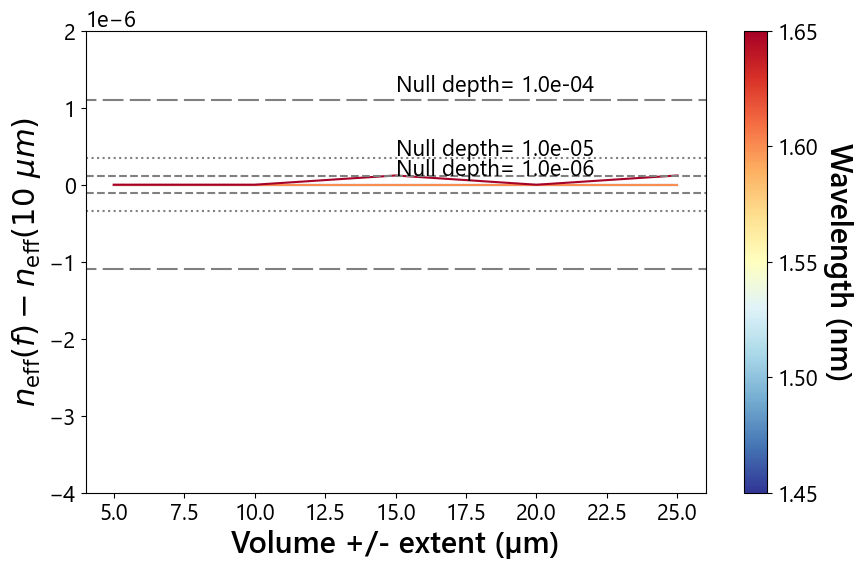

In [111]:
ind_PML = int(np.argwhere(PML_arr == 5.0))
ind_volume = int(np.argwhere(volume_arr == 5))

cmap = plt.get_cmap('RdYlBu_r')
norm = Normalize(vmin=min(wav_arr), vmax=max(wav_arr))
 
fig, ax = plt.subplots(figsize=(10, 6))
 
y = neff_cube[:, ind_PML, :] - neff_cube[:, ind_PML, 1][:, None]
 
for i, w in enumerate(wav_arr):
    ax.plot(volume_arr, y[i], color=cmap(norm(w)))
 
ntable = np.loadtxt(f'D:\\DATA\\SURF_2026\\ConvergenceTest\\Neff_tolerance.txt', delimiter=',', skiprows=1)
 
ax.axhline(ntable[3, 1], linestyle=(5, (10, 3)), color="grey")
ax.axhline(ntable[4, 1], linestyle="dotted", color="grey")
ax.axhline(ntable[5, 1], linestyle="dashed", color="grey")
 
ax.axhline(-ntable[3, 1], linestyle=(5, (10, 3)), color="grey")
ax.axhline(-ntable[4, 1], linestyle="dotted", color="grey")
ax.axhline(-ntable[5, 1], linestyle="dashed", color="grey")
 
ax.text(15, ntable[3, 1]*1.1, f"Null depth= {ntable[3, 0]:0.1e}", fontsize=16)
ax.text(15, ntable[4, 1]*1.1, f"Null depth= {ntable[4, 0]:0.1e}", fontsize=16)
ax.text(15, ntable[5, 1]*1.1, f"Null depth= {ntable[5, 0]:0.1e}", fontsize=16)
 
ax.set_xlabel("Volume +/- extent (µm)")
ax.set_ylabel(r"$n_{\rm eff}(f) - n_{\rm eff}(10\ µm)$")
 
sm = cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])
cbar = fig.colorbar(sm, ax=ax)
cbar.set_label('Wavelength (nm)', rotation=270, labelpad=25)
cbar.set_ticks(wav_arr)

plt.ylim(-4e-6, 2e-6)
 
plt.show()

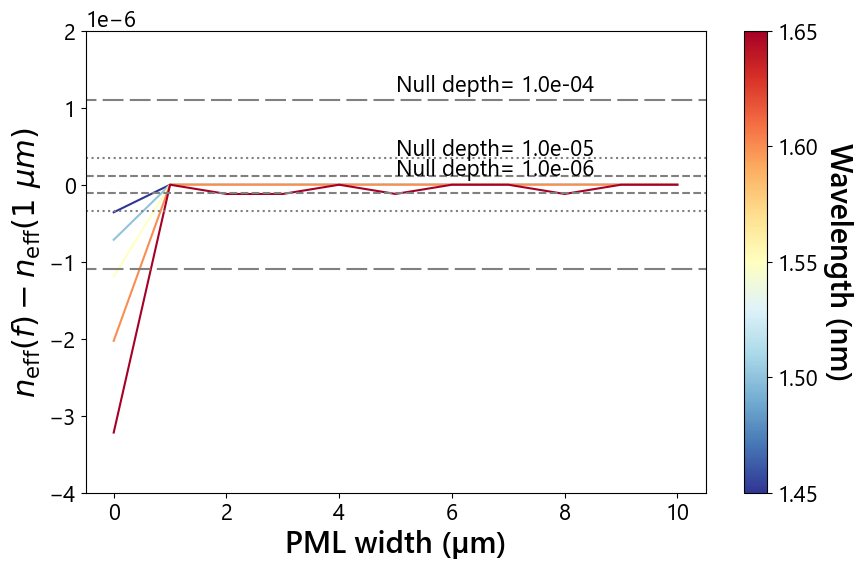

In [114]:
ind_PML = int(np.argwhere(PML_arr == 5.0))
ind_volume = int(np.argwhere(volume_arr == 5))

cmap = plt.get_cmap('RdYlBu_r')
norm = Normalize(vmin=min(wav_arr), vmax=max(wav_arr))
 
fig, ax = plt.subplots(figsize=(10, 6))
 
y = neff_cube[:, :, ind_volume] - neff_cube[:, 1, ind_volume][:, None]
 
for i, w in enumerate(wav_arr):
    ax.plot(PML_arr, y[i], color=cmap(norm(w)))
 
ntable = np.loadtxt(f'D:\\DATA\\SURF_2026\\ConvergenceTest\\Neff_tolerance.txt', delimiter=',', skiprows=1)
 
ax.axhline(ntable[3, 1], linestyle=(5, (10, 3)), color="grey")
ax.axhline(ntable[4, 1], linestyle="dotted", color="grey")
ax.axhline(ntable[5, 1], linestyle="dashed", color="grey")
 
ax.axhline(-ntable[3, 1], linestyle=(5, (10, 3)), color="grey")
ax.axhline(-ntable[4, 1], linestyle="dotted", color="grey")
ax.axhline(-ntable[5, 1], linestyle="dashed", color="grey")
 
ax.text(5, ntable[3, 1]*1.1, f"Null depth= {ntable[3, 0]:0.1e}", fontsize=16)
ax.text(5, ntable[4, 1]*1.1, f"Null depth= {ntable[4, 0]:0.1e}", fontsize=16)
ax.text(5, ntable[5, 1]*1.1, f"Null depth= {ntable[5, 0]:0.1e}", fontsize=16)
 
ax.set_xlabel("PML width (µm)")
ax.set_ylabel(r"$n_{\rm eff}(f) - n_{\rm eff}(1 \ µm)$")
 
sm = cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])
cbar = fig.colorbar(sm, ax=ax)
cbar.set_label('Wavelength (nm)', rotation=270, labelpad=25)
cbar.set_ticks(wav_arr)

plt.ylim(-4e-6, 2e-6)
 
plt.show()

# Straight waveguide: Generate $n_{\mathrm{eff}}$ table

In [19]:
np.arange(6.25, 6.8, 0.1)

array([6.25, 6.35, 6.45, 6.55, 6.65, 6.75])

In [20]:
# Define directories and files to work with
working_dir = "D:\\DATA\\ActivePIC\\SingleWaveguideConvergence\\"
save_dir = f"{working_dir}StraightWaveguide_neff_table\\"
os.makedirs(save_dir, exist_ok=True)
filename_root = "StraightWaveguide"
filename = f"{filename_root}.ind"

# Define parameter scan
grid_size = 0.05
grid_edge = 0.5
wav_arr = np.arange(1.45, 1.66, 0.01)
# wav_arr = np.array([1.45, 1.55, 1.65])
# width_arr = np.hstack([2.3, 2.35, np.arange(2.4, 3.4, 0.05)])
width_arr = np.arange(6.25, 6.8, 0.1)

for width in tqdm(width_arr, desc='Width loop', position=0, leave=False):
    width_str = f"{width:0.3f}".replace(".", "p")
    for wav in tqdm(wav_arr, desc='Wavelength loop', position=0, leave=False): 
        print(f'Wavelength: {wav} microns')
        wav_str = f"{wav:0.3f}".replace(".", "p")
    
        c = RSoftCircuit()
        c.read(working_dir+filename)
        c.set_symbol("free_space_wavelength", wav)
        c.set_symbol("width", width)
        c.set_symbol("height", 3.4)
        c.set_symbol("Contrast", 1.02)
        c.set_symbol("Grid_x", grid_size)
        c.set_symbol("Grid_y", grid_size)
        c.set_symbol("Grid_z", grid_size)
        c.set_symbol("Grid_Edge", grid_edge)
        c.set_symbol("PML_width", 5)
        c.set_symbol("Volume_transverse", width+10)
        c.write(working_dir+filename)

        prefix = f'{filename_root}_Wav{wav_str}_Width{width_str}'
        command = ["femsim", "-min", filename, "mode_method=1", "mode_set=1", "idbpm_convergence_warning=0",
                f"prefix={save_dir}/{prefix}", "wait=0"]

        print(f'Wavelength written: {rsoft_lib.read_symbol(working_dir+filename, "free_space_wavelength")}')
        print(f'Width written: {rsoft_lib.read_symbol(working_dir+filename, "width")}')
        
        # Run the command
        result = subprocess.run(command, cwd=working_dir, capture_output=True, text=True)

        metadata_name = f'{save_dir}{prefix}.json'
        symbols = rsoft_lib.export_symbols(working_dir+filename, metadata_name)

        filename_nef = f'{save_dir}{prefix}.nef'         
        sim = np.genfromtxt(filename_nef)
        neff = sim[1]
        print(f"n_eff: {neff}")

        # Keep only the necessary output files to save storage
        keep_ext = ['.mon', '.json', '.dat', '.nef', '.m00', '.m01']
        p = Path(save_dir+prefix)
        for f in p.parent.glob(p.name + "*"):
            if f.is_file() and not f.name.lower().endswith(tuple(e.lower() for e in keep_ext)):
                f.unlink()

np.save(f"{save_dir}{filename_root}_Wav_midpoint.npy", wav_arr)
# wav_arr_previous = np.load(f"{save_dir}{filename_root}_Wav.npy")
# np.save(f"{save_dir}{filename_root}_Wav.npy", np.append(wav_arr_previous, wav_arr))
np.save(f"{save_dir}{filename_root}_Width_midpoint.npy", width_arr)

Width loop:   0%|          | 0/6 [00:00<?, ?it/s]

Wavelength loop:   0%|          | 0/21 [00:00<?, ?it/s]

Wavelength: 1.45 microns
Wavelength written: 1.45
Width written: 6.25
n_eff: [1.         1.46415281 0.        ]


Wavelength loop:   5%|▍         | 1/21 [05:28<1:49:38, 328.92s/it]

Wavelength: 1.46 microns
Wavelength written: 1.46
Width written: 6.25
n_eff: [1.         1.46394002 0.        ]


Wavelength loop:  10%|▉         | 2/21 [11:17<1:47:44, 340.22s/it]

... (253 outputs left out)

Wavelength loop:  95%|█████████▌| 20/21 [1:34:35<04:40, 280.01s/it]

n_eff: [1.         1.46042561 0.        ]
Wavelength: 1.6500000000000001 microns
Wavelength written: 1.65
Width written: 6.75


Wavelength loop: 100%|██████████| 21/21 [1:39:29<00:00, 284.15s/it]

n_eff: [1.         1.46020877 0.        ]


Compile into a table of $n_{\mathrm{eff}}$ as a function of wavelength and waveguide width

In [2]:
import pandas as pd

# --------------------------------------------------------------------- #
# Config -- must match the scan script
# --------------------------------------------------------------------- #
working_dir = "D:\\DATA\\ActivePIC\\SingleWaveguideConvergence\\"
save_dir = f"{working_dir}StraightWaveguide_neff_table\\"
filename_root = "StraightWaveguide"

# --------------------------------------------------------------------- #
# Load the swept parameter arrays
# --------------------------------------------------------------------- #
# wav_arr = np.load(f"{save_dir}{filename_root}_Wav_midpoint.npy")
# width_arr = np.load(f"{save_dir}{filename_root}_Width_midpoint.npy")
wav_arr = np.arange(1.45, 1.66, 0.01)
width_arr = np.arange(2.3, 6.8, 0.05)

n_wav, n_width = len(wav_arr), len(width_arr)

# --------------------------------------------------------------------- #
# Load n_eff (real + imaginary parts) for every (width, wavelength) pair.
# Missing/unreadable files become NaN rather than crashing the whole load
# -- given how many runs in this conversation have failed partway through
# a sweep, this is not a hypothetical concern.
# --------------------------------------------------------------------- #
neff_real = np.full((n_width, n_wav), np.nan)
neff_imag = np.full((n_width, n_wav), np.nan)

n_missing = 0
for iw, width in enumerate(width_arr):
    width_str = f"{width:0.3f}".replace(".", "p")
    for il, wav in enumerate(wav_arr):
        wav_str = f"{wav:0.3f}".replace(".", "p")
        fn = f'{save_dir}{filename_root}_Wav{wav_str}_Width{width_str}.nef'
        try:
            sim = np.genfromtxt(fn)
            neff_real[iw, il] = sim[1]
            neff_imag[iw, il] = sim[2] if sim.size > 2 else 0.0
        except (FileNotFoundError, IndexError, OSError):
            n_missing += 1

if n_missing:
    print(f"Warning: {n_missing} of {n_width * n_wav} (width, wavelength) "
          f"combinations had no readable .nef file and are NaN in the table.")

# --------------------------------------------------------------------- #
# Wide-format tables: rows = width, columns = wavelength
# --------------------------------------------------------------------- #
wav_cols = [f"{w:.3f}" for w in wav_arr]
width_index = [f"{w:.3f}" for w in width_arr]

df_neff_real = pd.DataFrame(neff_real, index=width_index, columns=wav_cols)
df_neff_real.index.name = "width (um)"
df_neff_real.columns.name = "wavelength (um)"

df_neff_imag = pd.DataFrame(neff_imag, index=width_index, columns=wav_cols)
df_neff_imag.index.name = "width (um)"
df_neff_imag.columns.name = "wavelength (um)"

# df_neff_real.to_csv(f"{save_dir}{filename_root}_neff_real_table.csv")
# df_neff_imag.to_csv(f"{save_dir}{filename_root}_neff_imag_table.csv")

# --------------------------------------------------------------------- #
# Long-format table: one row per (wavelength, width) pair, with columns
# in the order (wavelength, width, neff) -- this is usually the more
# convenient format for plotting/filtering than the wide pivoted table.
# --------------------------------------------------------------------- #
width_grid, wav_grid = np.meshgrid(width_arr, wav_arr, indexing="ij")
df_long = pd.DataFrame({
    "wavelength": wav_grid.ravel(),
    "width": width_grid.ravel(),
    "neff": neff_real.ravel(),
    "neff_imag": neff_imag.ravel(),
})
df_long.to_csv(f"{save_dir}{filename_root}_neff_long_midpoint.csv", index=False)

print(f"\nWrote:")
# print(f"  {save_dir}{filename_root}_neff_real_table.csv  (wide, {n_width}x{n_wav})")
# print(f"  {save_dir}{filename_root}_neff_imag_table.csv  (wide, {n_width}x{n_wav})")
print(f"  {save_dir}{filename_root}_neff_long_midpoint.csv         (long, {n_width*n_wav} rows, "
      f"columns: wavelength, width, neff, neff_imag)")

print("\nLong-format table preview:")
print(df_long.round(5).head(10))

ValueError: setting an array element with a sequence.

In [4]:
# import os

import matplotlib as mpl
import matplotlib.animation as animation
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from tqdm import tqdm

import rsoft_lib as rlib

# # --------------------------------------------------------------------- #
# # Config -- must match the scan script
# # --------------------------------------------------------------------- #
# working_dir = "D:\\DATA\\ActivePIC\\SingleWaveguideConvergence\\"
# save_dir = f"{working_dir}StraightWaveguide_neff_table\\"
# filename_root = "StraightWaveguide"
# height = 3.4                  # guide height: the fundamental TE (Ex-dominant) mode is m01 below this width, m00 from it
# verify = True                 # read the Ex and Ey files of every selected mode and check it is Ex-dominant (slow)
# movie_wavs = [1.45, 1.55, 1.65]   # wavelengths for the HTML viewers; None = all
# zoom = 6.0                    # half-window in μm for the viewers; None = full domain

# wav_arr = np.arange(1.45, 1.66, 0.01)
# width_arr = np.arange(2.3, 6.8, 0.05)
# n_wav, n_width = len(wav_arr), len(width_arr)

# # --------------------------------------------------------------------- #
# # n_eff of the fundamental TE mode for every (width, wavelength) pair
# # --------------------------------------------------------------------- #
# neff_real = np.full((n_width, n_wav), np.nan)
# neff_imag = np.full((n_width, n_wav), np.nan)
# mode_num = np.full((n_width, n_wav), -1)          # which mode (the NN of .mNN) the n_eff comes from
# ex_over_ey = np.full((n_width, n_wav), np.nan)    # Ex peak / Ey peak of that mode, if verify

# n_missing = n_no_mode = 0
# for iw, width in enumerate(tqdm(width_arr, desc="Widths")):
#     k = rlib.ex_mode_index(width, height)         # 1 for width < height, else 0
#     for il, wav in enumerate(wav_arr):
#         stem = f"{save_dir}{filename_root}_Wav{rlib.param_str(wav)}_Width{rlib.param_str(width)}"
#         try:
#             nef = np.atleast_2d(np.genfromtxt(stem + ".nef"))     # one row per mode: [index, n_eff (, imaginary part)]
#         except (FileNotFoundError, OSError):
#             n_missing += 1
#             continue
#         if k >= len(nef):
#             n_no_mode += 1                                        # that mode was not computed in this run
#             continue
#         neff_real[iw, il] = nef[k, 1]
#         neff_imag[iw, il] = nef[k, 2] if nef.shape[1] > 2 else 0.0
#         mode_num[iw, il] = k
#         if verify:
#             try:
#                 ex = rlib.read_mode(f"{stem}_ex.m{k:02d}")
#                 ey = rlib.read_mode(f"{stem}_ey.m{k:02d}")
#                 ex_over_ey[iw, il] = ex.peak_amp() / ey.peak_amp()
#             except (FileNotFoundError, OSError, ValueError):
#                 pass

# if n_missing:
#     print(f"Warning: {n_missing} of {n_width * n_wav} (width, wavelength) combinations had no readable .nef file.")
# if n_no_mode:
#     print(f"Warning: {n_no_mode} .nef files do not contain the required mode (too few modes computed).")

# # --------------------------------------------------------------------- #
# # Long-format table
# # --------------------------------------------------------------------- #
# width_grid, wav_grid = np.meshgrid(width_arr, wav_arr, indexing="ij")
# df_long = pd.DataFrame({
#     "wavelength": wav_grid.ravel(),
#     "width": width_grid.ravel(),
#     "neff": neff_real.ravel(),
#     "neff_imag": neff_imag.ravel(),
#     "mode": [("m%02d" % m) if m >= 0 else "" for m in mode_num.ravel()],
# })
# if verify:
#     df_long["ex_over_ey"] = ex_over_ey.ravel()
#     # at width == height the TE/TM modes are degenerate, so the stored mode is a mixture and Ex/Ey is not large
#     df_long["is_TE"] = (df_long.ex_over_ey > 10) | (np.isclose(df_long.width, height) & (df_long.ex_over_ey > 0.3))
# df_long.to_csv(f"{save_dir}{filename_root}_neff.csv", index=False)
# print(f"\nWrote {save_dir}{filename_root}_neff.csv ({len(df_long)} rows)")

# if verify:
#     checked = df_long.ex_over_ey.notna()
#     bad = df_long[checked & ~df_long.is_TE]
#     print(f"Checked {checked.sum()} modes: {len(bad)} are NOT Ex-dominant (the table value would be the wrong mode).")
#     if len(bad):
#         print(bad.round(5).to_string(index=False))

# print("\nLong-format table preview:")
# print(df_long.round(5).head(10))

# --------------------------------------------------------------------- #
# Interactive HTML viewers: the mode behind each table entry (Ex and Ey), one file per wavelength,
# one frame per width. Uses the same mode_field() lookup as the library, so the file shown is the
# one whose n_eff is in the table.
# --------------------------------------------------------------------- #
mpl.rcParams["animation.embed_limit"] = 200   # MB
out_dir = f"{save_dir}mode_movies_table\\"
os.makedirs(out_dir, exist_ok=True)

for wav in tqdm(wav_arr if movie_wavs is None else movie_wavs, desc="HTML viewers"):
    wav = wav_arr[np.argmin(np.abs(wav_arr - wav))]
    frames = []
    for width in width_arr:
        try:
            path, neff = rlib.mode_field(wav, width, mode_dir=save_dir, height=height)
            fx, fy = rlib.read_mode(path), rlib.read_mode(path.replace("_ex.m0", "_ey.m0"))
        except (FileNotFoundError, OSError, IndexError, ValueError):
            continue
        sx, sy = fx.signed_field(), fy.signed_field()
        peak = max(np.abs(sx).max(), np.abs(sy).max())
        frames.append((width, os.path.splitext(path)[1][1:], neff, sx / peak, sy / peak))
    if not frames:
        continue

    extent = (fx.x[0], fx.x[-1], fx.y[0], fx.y[-1])
    fig, ax = plt.subplots(1, 2, figsize=(10, 4.8), dpi=100, sharex=True, sharey=True, constrained_layout=True)
    ims = [a.imshow(frames[0][3 + j], extent=extent, origin="lower", cmap="RdBu_r", vmin=-1, vmax=1)
           for j, a in enumerate(ax)]
    for a, name in zip(ax, ("$E_x$", "$E_y$")):
        a.set_title(name)
        a.set_xlabel("x (μm)")
        if zoom:
            a.set_xlim(-zoom, zoom)
            a.set_ylim(-zoom, zoom)
    ax[0].set_ylabel("y (μm)")
    fig.colorbar(ims[1], ax=ax, label="field / mode peak", shrink=0.8)
    title = fig.suptitle("")

    def update(i):
        width, ext, neff, sx, sy = frames[i]
        ims[0].set_data(sx)
        ims[1].set_data(sy)
        title.set_text(f"λ = {wav:.3f} μm, width = {width:.3f} μm, {ext}, n_eff = {neff:.5f}")
        return ims

    anim = animation.FuncAnimation(fig, update, frames=len(frames), blit=False)
    anim.save(f"{out_dir}{filename_root}_Wav{rlib.param_str(wav)}_table_modes.html",
              writer=animation.HTMLWriter(fps=4, embed_frames=True))
    plt.close(fig)
print(f"Saved the HTML viewers to {out_dir}")

HTML viewers:   0%|          | 0/3 [00:00<?, ?it/s]

HTML viewers: 100%|██████████| 3/3 [04:25<00:00, 88.67s/it]

Saved the HTML viewers to D:\DATA\ActivePIC\SingleWaveguideConvergence\StraightWaveguide_neff_table\mode_movies_table\


Plot $n_{\mathrm{eff}}$ table

In [29]:
filename_BP = 'D:\\DATA\\ActivePIC\\AchromaticPhaseDelay\\TwoWaveguideTest\\TwoWaveguides_FemSIM_LengthMod_FilePower.mon'
wav_arr= [1.55]
monitors = rsoft_lib.read_monitor(filename_BP)
Neff, wav = 1.457897067, 1.55
phase_sim = ((monitors.values[:, 3]-monitors.values[0, 1]) + 360)%360
phase_est = 180/np.pi * (2*np.pi/wav) * Neff * (monitors.z - monitors.z[0])
phase_est = phase_est % 360
dLength_pi = wav/(2*Neff) + monitors.z[0]

def extract_s(z, phase_monitor_deg, phase_expected_deg):
    """
    z: 1D array, propagation distance (µm) for ONE wavelength
    phase_monitor_deg: BeamPROP phase at each z, wrapped 0-360 (deg) - the orange points
    phase_expected_deg: predicted phase at each z, wrapped 0-360 (deg) - the black dashed line
    Returns: s (slope), intercept (deg, should be ~0 if no launch-phase offset)
    """
    # unwrap needs radians
    monitor_unwrapped = np.degrees(np.unwrap(np.radians(phase_monitor_deg)))
    expected_unwrapped = np.degrees(np.unwrap(np.radians(phase_expected_deg)))

    # fit monitor = s * expected + intercept  (free intercept - don't force through
    # origin, since a nonzero intercept here is itself diagnostic: it's the
    # launch/coupling phase offset the multi-step method exists to isolate)
    A = np.vstack([expected_unwrapped, np.ones_like(expected_unwrapped)]).T
    s, intercept = np.linalg.lstsq(A, monitor_unwrapped, rcond=None)[0]
    return s, intercept

# If you have this per wavelength (e.g. z_arr same for all, phase arrays shape (n_wav, n_z)):
s_vals = np.zeros_like(wav_arr, dtype=float)
intercepts = np.zeros_like(wav_arr, dtype=float)
s_vals, intercepts = extract_s(monitors.z, phase_sim, phase_est)

In [30]:
s_vals

1.0001257409625468

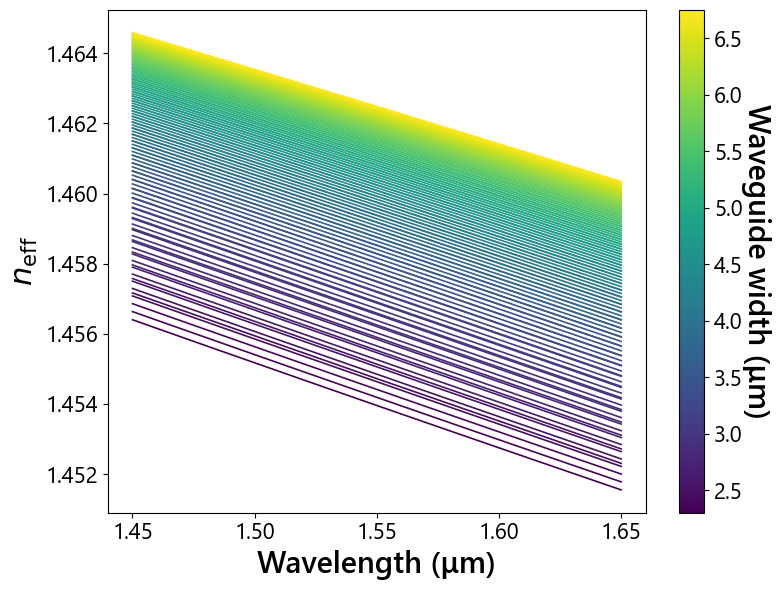

In [5]:
"""
Plot n_eff vs wavelength, with one curve per waveguide width, colored by
width using a continuous colormap + colorbar (rather than a discrete
per-width legend, which would be unreadable for a wide width scan).
"""

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.cm as cm
from matplotlib.colors import Normalize

# --------------------------------------------------------------------- #
# Config -- must match the scan / compile-table scripts
# --------------------------------------------------------------------- #
working_dir = "D:\\DATA\\ActivePIC\\SingleWaveguideConvergence\\"
save_dir = f"{working_dir}StraightWaveguide_neff_table\\"
filename_root = "StraightWaveguide"

# --------------------------------------------------------------------- #
# Load the long-format table produced by compile_neff_table.py
# --------------------------------------------------------------------- #
df = pd.read_csv(f"{save_dir}{filename_root}_neff.csv")

widths = np.sort(df["width"].unique())

# --------------------------------------------------------------------- #
# Colormap setup: map width -> color continuously
# --------------------------------------------------------------------- #
cmap = plt.get_cmap("viridis")
norm = Normalize(vmin=widths.min(), vmax=widths.max())
sm = cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])  # required for older matplotlib versions to allow colorbar() without data

fig, ax = plt.subplots(figsize=(8, 6))

for width in widths:
    sub = df[df["width"] == width].sort_values("wavelength")
    ax.plot(sub["wavelength"], sub["neff"], color=cmap(norm(width)), linewidth=1.2)

df = pd.read_csv(f"{save_dir}{filename_root}_neff_long_midpoint.csv")
widths = np.sort(df["width"].unique())

for width in widths:
    sub = df[df["width"] == width].sort_values("wavelength")
    ax.plot(sub["wavelength"], sub["neff"], color=cmap(norm(width)), linewidth=1.2)

cbar = fig.colorbar(sm, ax=ax)
cbar.set_label("Waveguide width (\u03bcm)", rotation=270, labelpad=20)

ax.set_xlabel("Wavelength (\u03bcm)")
ax.set_ylabel("$n_\mathrm{eff}$")

fig.tight_layout()
fig.savefig(f"{save_dir}{filename_root}_neff_vs_wavelength_by_width.png", dpi=150)
plt.show()

# Straight waveguide: Generate $n_{\mathrm{eff}}$ table as a function of temperature

In [18]:
# Define directories and files to work with
working_dir = "D:\\DATA\\ActivePIC\\SingleWaveguideConvergence\\"
save_dir = f"{working_dir}StraightWaveguide_neff_table_with_temperature\\"
os.makedirs(save_dir, exist_ok=True)
filename_root = "StraightWaveguide_temperature"
CAD_path = os.path.join(working_dir, f"{filename_root}.ind")

# Define parameter scan
grid_size = 0.05
grid_edge = 0.5
height = 3.4
wav_arr = np.arange(1.45, 1.66, 0.05)
# width_arr = np.arange(2.3, 7.0, 0.3)
width_arr = [3.4]
temp_arr = np.linspace(0, 100, 6)

# Keep the .nef table and every mode file; delete the rest (.msh, .pdr, ...). keep_ext=None keeps everything.
keep_ext = (".mon", ".json", ".dat", ".nef", ".ipf", ".src", ".t", ".m[0-9][0-9]", ".m[0-9][0-9][0-9]")
from tqdm.auto import tqdm            # instead of: from tqdm import tqdm

for temp in tqdm(temp_arr[1:], desc='Temp loop', leave=False):
    for width in tqdm(width_arr, desc='Width loop', position=0, leave=False):
        k = rlib.ex_mode_index(width, height)               # 1 below width = height, else 0: the fundamental TE mode
        for wav in tqdm(wav_arr, desc='Wavelength loop', position=0, leave=False):
            prefix = os.path.join(save_dir, f"{filename_root}_Wav{rlib.param_str(wav)}"
                                            f"_Width{rlib.param_str(width)}_Temp{rlib.param_str(temp)}")
            rlib.run_sim(
                CAD_path,
                prefix=prefix,
                symbols={
                    "free_space_wavelength": wav,
                    "width": width,
                    "height": height,
                    "Temp": temp,
                    "Contrast": 1.02,
                    "Grid_x": grid_size,
                    "Grid_y": grid_size,
                    "Grid_z": grid_size,
                    "Grid_Edge": grid_edge,
                    "PML_width": 5,
                    "Volume_transverse": width + 10,
                },
                exe="femsim",
                args=["mode_method=1", "mode_set=1", "idbpm_convergence_warning=0"],
                keep_ext=keep_ext,
            )

            nef = np.atleast_2d(np.genfromtxt(prefix + ".nef"))     # one row per mode: [index, n_eff (, imaginary part)]
            tqdm.write(f"T = {temp:g}, W = {width:.3f}, wav = {wav:.3f}: {len(nef)} modes, n_eff = {nef[k, 1]:.5f}")

np.save(f"{save_dir}{filename_root}_Wav.npy", wav_arr)
np.save(f"{save_dir}{filename_root}_Width.npy", width_arr)
np.save(f"{save_dir}{filename_root}_Temp.npy", temp_arr)

Wavelength loop:  20%|██        | 1/5 [1:57:49<7:51:16, 7069.02s/it]

T = 20, W = 3.400, wav = 1.450: 4 modes, n_eff = 1.46036


Wavelength loop:  40%|████      | 2/5 [3:16:56<4:45:10, 5703.39s/it]

T = 20, W = 3.400, wav = 1.500: 4 modes, n_eff = 1.45917


Wavelength loop:  60%|██████    | 3/5 [4:20:06<2:40:59, 4829.89s/it]

T = 20, W = 3.400, wav = 1.550: 4 modes, n_eff = 1.45799


... (39 outputs left out)

T = 100, W = 3.400, wav = 1.550: 4 modes, n_eff = 1.45833


Wavelength loop:  80%|████████  | 4/5 [3:14:05<47:12, 2832.92s/it]  

T = 100, W = 3.400, wav = 1.600: 4 modes, n_eff = 1.45714


T = 100, W = 3.400, wav = 1.650: 4 modes, n_eff = 1.45595


In [ ]:
working_dir = "D:\\DATA\\ActivePIC\\SingleWaveguideConvergence\\"
save_dir = f"{working_dir}StraightWaveguide_neff_table_with_temperature\\"
filename_root = "StraightWaveguide_temperature"
height = 3.4

wavs = np.arange(1.45, 1.66, 0.05)
widths = np.array([3.4])                      # e.g. np.arange(2.3, 7.0, 0.3) for the full scan
temps = np.linspace(0, 100, 6)

rows = []
for W in widths:
    for wav in wavs:
        points = []                           # (temperature, n_eff) of the runs that exist
        for T in temps:
            path = os.path.join(save_dir, f"{filename_root}_Wav{rlib.param_str(wav)}_Width{rlib.param_str(W)}_Temp{rlib.param_str(T)}.nef")
            if os.path.exists(path):
                nef = np.atleast_2d(np.genfromtxt(path))
                points.append((T, nef[rlib.ex_mode_index(W, height), 1]))
        if not points:
            continue
        T_arr, n_arr = np.array(points).T
        slope, intercept = np.polyfit(T_arr, n_arr, 1) if len(points) >= 2 else (np.nan, np.nan)      # straight-line fit in temperature
        for T, n in points:
            fit = slope * T + intercept
            rows.append(dict(width=W, wavelength=round(wav, 3), temperature=T, neff=n,
                             neff_fit=fit, deviation=n - fit, dneff_dT=slope))

df = pd.DataFrame(rows)
df.to_csv(f"{save_dir}{filename_root}_neff_table.csv", index=False)
print(df.to_string(index=False))

 width  wavelength  temperature     neff  neff_fit     deviation  dneff_dT
   3.4        1.45         20.0 1.460361  1.460361  2.384000e-07  0.000004
   3.4        1.45         40.0 1.460447  1.460448 -4.176000e-07  0.000004
   3.4        1.45         60.0 1.460535  1.460535  3.999998e-10  0.000004
   3.4        1.45         80.0 1.460622  1.460621  2.984000e-07  0.000004
   3.4        1.45        100.0 1.460708  1.460708 -1.196000e-07  0.000004
   3.4        1.50         20.0 1.459174  1.459174 -9.520000e-08  0.000004
   3.4        1.50         40.0 1.459261  1.459261  1.170000e-08  0.000004
   3.4        1.50         60.0 1.459347  1.459347 -2.384000e-07  0.000004
   3.4        1.50         80.0 1.459435  1.459434  8.225000e-07  0.000004
   3.4        1.50        100.0 1.459521  1.459521 -5.006000e-07  0.000004
   3.4        1.55         20.0 1.457985  1.457985 -4.760000e-08  0.000004
   3.4        1.55         40.0 1.458072  1.458072 -1.908000e-07  0.000004
   3.4        1.55       

25 of 25 runs found: 1 widths, 5 temperatures, 5 wavelengths


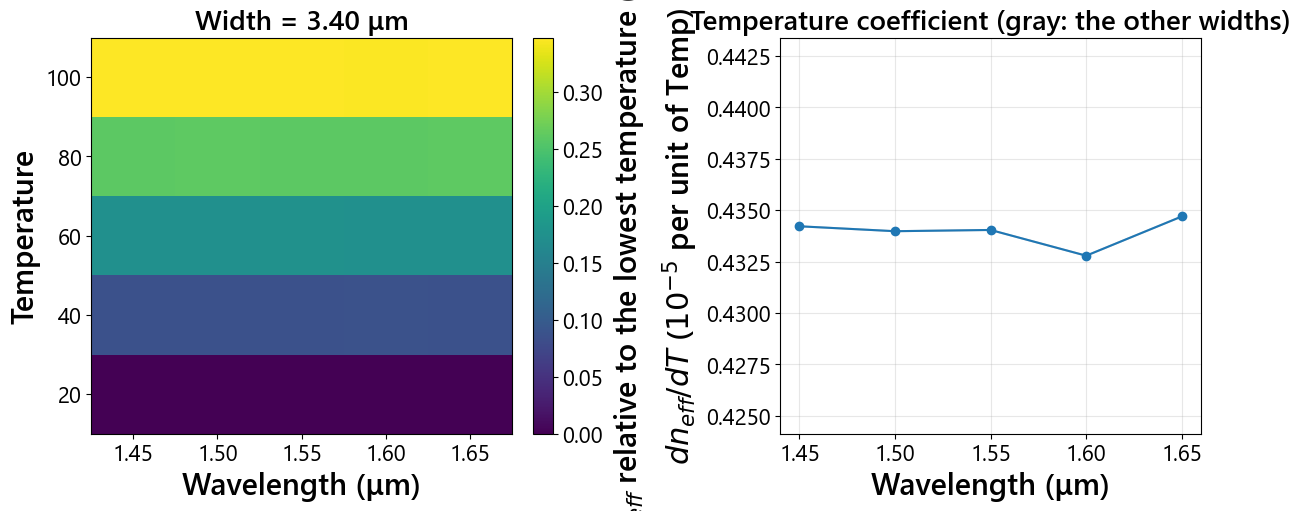

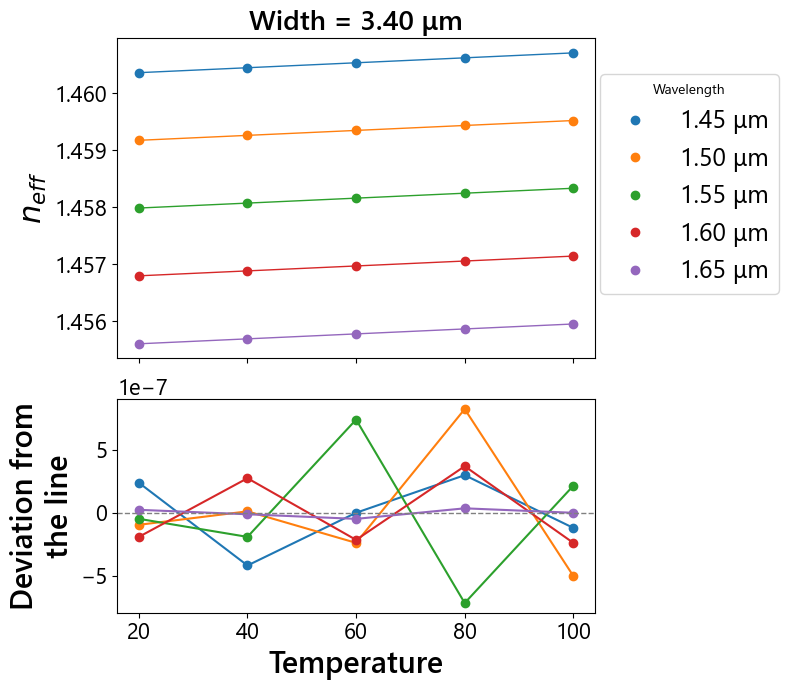

In [30]:
# import os

# import matplotlib.pyplot as plt
# import numpy as np
# from matplotlib.animation import FuncAnimation, PillowWriter
from matplotlib.cm import ScalarMappable
# from matplotlib.colors import Normalize

# import rsoft_lib as rlib

working_dir = "D:\\DATA\\ActivePIC\\SingleWaveguideConvergence\\"
save_dir = f"{working_dir}StraightWaveguide_neff_table_with_temperature\\"
filename_root = "StraightWaveguide_temperature"
height = 3.4

# The scan axes (the scan saves them as .npy files only when it has finished; edit these lines if you changed the scan)
wavs = np.arange(1.45, 1.66, 0.05)
widths = np.array([3.4])                      # e.g. np.arange(2.3, 7.0, 0.3) for the full scan
temps = np.linspace(0, 100, 6)


def neff_of(wav, width, temp):
    """n_eff of the fundamental TE mode, or NaN if that run has not finished."""
    path = os.path.join(save_dir, f"{filename_root}_Wav{rlib.param_str(wav)}_Width{rlib.param_str(width)}_Temp{rlib.param_str(temp)}.nef")
    if not os.path.exists(path):
        return np.nan
    nef = np.atleast_2d(np.genfromtxt(path))
    return nef[rlib.ex_mode_index(width, height), 1]


neff = np.array([[[neff_of(w, W, T) for w in wavs] for T in temps] for W in widths])      # [width, temperature, wavelength]
have_T = np.isfinite(neff).any(axis=(0, 2))
have_W = np.isfinite(neff).any(axis=(1, 2))
if not have_T.any():
    raise RuntimeError("No finished runs found in " + save_dir)
temps, widths, neff = temps[have_T], widths[have_W], neff[have_W][:, have_T]
print(f"{np.isfinite(neff).sum()} of {neff.size} runs found: {len(widths)} widths, {len(temps)} temperatures, {len(wavs)} wavelengths")

# n_eff change relative to the lowest temperature available, and dn_eff/dT from a straight-line fit in temperature
dn = np.full_like(neff, np.nan)
dndT = np.full((len(widths), len(wavs)), np.nan)
for i in range(len(widths)):
    for j in range(len(wavs)):
        ok = np.isfinite(neff[i, :, j])
        if ok.any():
            dn[i, :, j] = neff[i, :, j] - neff[i, ok, j][0]
        if ok.sum() >= 2:
            dndT[i, j] = np.polyfit(temps[ok], neff[i, ok, j], 1)[0]

# ---- 2D maps of the change in n_eff against wavelength and temperature, one frame per width
norm = Normalize(vmin=0, vmax=np.nanmax(dn) * 1e3)
fig, (ax_map, ax_line) = plt.subplots(1, 2, figsize=(12, 5), constrained_layout=True)
fig.colorbar(ScalarMappable(norm=norm, cmap='viridis'), ax=ax_map, label=r'$\Delta n_{eff}$ relative to the lowest temperature ($10^{-3}$)')


def draw(i):
    ax_map.clear()
    ax_line.clear()
    ax_map.pcolormesh(wavs, temps, dn[i] * 1e3, shading='nearest', cmap='viridis', norm=norm)
    ax_map.set(xlabel='Wavelength (μm)', ylabel='Temperature', title=f'Width = {widths[i]:.2f} μm')
    for k in range(len(widths)):
        ax_line.plot(wavs, dndT[k] * 1e5, color='lightgray', zorder=1)
    ax_line.plot(wavs, dndT[i] * 1e5, 'o-', color='C0', zorder=2)
    ax_line.set(xlabel='Wavelength (μm)', ylabel=r'$dn_{eff}/dT$ ($10^{-5}$ per unit of Temp)',
                ylim=(np.nanmin(dndT) * 1e5 * 0.98, np.nanmax(dndT) * 1e5 * 1.02))
    ax_line.set_title('Temperature coefficient (gray: the other widths)')
    ax_line.grid(alpha=0.3)


if len(widths) > 1:
    gif_path = f"{save_dir}{filename_root}_widths.gif"
    FuncAnimation(fig, draw, frames=len(widths)).save(gif_path, writer=PillowWriter(fps=1))
    print("Saved", gif_path)
    try:                                                      # show the animation in the notebook
        from IPython.display import Image, display
        display(Image(filename=gif_path))
    except ImportError:
        pass
else:
    draw(0)
    fig.savefig(f"{save_dir}{filename_root}_map.png", dpi=200, bbox_inches='tight')
    plt.show()
plt.close(fig)

# ---- n_eff against temperature for each wavelength (is it a straight line?), for the width closest to 3.4 um
i = int(np.argmin(np.abs(widths - 3.4)))
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(8, 7), sharex=True, gridspec_kw={'height_ratios': [3, 2]})
for j, wav in enumerate(wavs):
    ok = np.isfinite(neff[i, :, j])
    if ok.sum() < 2:
        continue
    slope, intercept = np.polyfit(temps[ok], neff[i, ok, j], 1)
    ax1.plot(temps[ok], neff[i, ok, j], 'o', color=f'C{j}', label=f'{wav:.2f} μm')
    ax1.plot(temps[ok], slope * temps[ok] + intercept, '-', color=f'C{j}', linewidth=1)
    ax2.plot(temps[ok], (neff[i, ok, j] - (slope * temps[ok] + intercept)), 'o-', color=f'C{j}')
ax1.set_ylabel(r'$n_{eff}$')
ax1.set_title(f'Width = {widths[i]:.2f} μm')
ax1.legend(title='Wavelength', loc=(1.01, 0.2))
ax2.axhline(0, color='grey', linestyle='dashed', linewidth=1)
ax2.set_xlabel('Temperature')
ax2.set_ylabel('Deviation from\nthe line')
plt.tight_layout()
plt.savefig(f"{save_dir}{filename_root}_neff_vs_temperature.png", dpi=200, bbox_inches='tight')
plt.show()

__Last computed:__
Wavelength loop:  60%|██████    | 3/5 [19:59<13:38, 409.29s/it]
n_eff: 1.460745692
Wavelength written: 1.6
Width written: 4.9
Temp written: 0

In [8]:
import re
import shutil

ind = r"D:\DATA\NullingPIC_Gen2_sims\P-02_SideStepBend\P-02_SideStepBend.ind"
shutil.copy(ind, ind + ".bak")                                     # backup first

with open(ind, newline="") as f:                                   # newline="" keeps the Windows line endings
    lines = f.read().splitlines(keepends=True)
bad = [i for i, l in enumerate(lines) if re.match(r"\s*<", l)]      # lines that start with '<': unfilled placeholders
for i in bad:
    print(f"removing line {i + 1}: {lines[i].strip()}")
with open(ind, "w", newline="") as f:
    f.writelines(l for i, l in enumerate(lines) if i not in bad)

removing line 2: <pade symbol> = <value for (2,2)>


# Simulated bend: grid size vs. grid edge factor

In [3]:
# Define directories and files to work with
working_dir = "D:\\DATA\\ActivePIC\\SingleWaveguideConvergence\\"
save_dir = f"{working_dir}StraightWaveguide_simulatedBend_scan_gridSize_gridEdgeFactor\\"
os.makedirs(save_dir, exist_ok=True)
filename_root = "StraightWaveguide_simulatedBend"
filename = f"{filename_root}.ind"

# Define parameter scan
# grid_size_arr = [0.05, 0.06, 0.07, 0.08, 0.09, *np.arange(0.1, 0.7, 0.1)]
grid_size_arr = [0.01]#, 0.02, 0.03]#, 0.04, 0.05]
grid_edge_arr = np.arange(0.1, 1.1, 0.1)
wav_arr = np.linspace (1.45, 1.65, 5)

# neff_real, neff_imag = 1.46, -0.00001

for wav in tqdm(wav_arr, desc='Wavelength loop', position=0, leave=False): 
    print(f'Wavelength: {wav} microns')
    wav_str = f"{wav:0.3f}".replace(".", "p")
    for grid_size in tqdm(grid_size_arr[::-1], desc='Grid size loop', position=0, leave=False):
        grid_size_str = f"{grid_size:0.3f}".replace(".", "p")
        for grid_edge in tqdm(grid_edge_arr[::-1], desc='Grid edge loop', position=0, leave=False):  
            grid_edge_str = f"{grid_edge:0.3f}".replace(".", "p")

            c = RSoftCircuit()
            c.read(working_dir+filename)
            c.set_symbol("free_space_wavelength", wav)
            c.set_symbol("Contrast", 1.02)
            c.set_symbol("Grid_x", grid_size)
            c.set_symbol("Grid_y", grid_size)
            c.set_symbol("Grid_z", grid_size)
            c.set_symbol("Grid_Edge", grid_edge)
            c.set_symbol("PML_width", 5)
            c.set_symbol("Volume_transverse", 25)
            c.set_symbol("simulated_bend_radius", 300)
            # c.set_symbol("Starting_Neff_real", neff_real)
            # c.set_symbol("Starting_Neff_imag", neff_imag)
            c.write(working_dir+filename)
            
            command = ["femsim", "-min", filename, "mode_method=1", "mode_set=1", "idbpm_convergence_warning=0",
                    f"prefix={save_dir}{filename_root}_Wav{wav_str}_GridSize{grid_size_str}_GridEdge{grid_edge_str}", "wait=0"]

            print(f'Wavelength written: {rsoft_lib.read_symbol(working_dir+filename, "free_space_wavelength")}')
            print(f'Grid size written: {rsoft_lib.read_symbol(working_dir+filename, "Grid_x")}')
            print(f'Grid edge factor written: {rsoft_lib.read_symbol(working_dir+filename, "Grid_Edge")}')
            
            # Run the command
            result = subprocess.run(command, cwd=working_dir, capture_output=True, text=True)

            metadata_name = f'{save_dir}{filename_root}_Wav{wav_str}_GridSize{grid_size_str}_GridEdge{grid_edge_str}.json'
            symbols = rsoft_lib.export_symbols(working_dir+filename, metadata_name)

            # filename_nef = f'{save_dir}{filename_root}_Wav{wav_str}_GridSize{grid_size_str}_GridEdge{grid_edge_str}.nef'         
            # sim = np.genfromtxt(filename_nef)
            # neff_real, neff_imag = sim[0,1], sim[0,2]
            # print(f"n_eff: {neff_real}, {neff_imag}")

np.save(f"{save_dir}{filename_root}_Wav.npy", wav_arr)
# grid_size_arr_old = np.load(f"{save_dir}{filename_root}_GridSize.npy")
np.save(f"{save_dir}{filename_root}_GridSize.npy", grid_size_arr)
# grid_edge_arr_old = np.load(f"{save_dir}{filename_root}_GridEdge.npy")
np.save(f"{save_dir}{filename_root}_GridEdge.npy", grid_edge_arr)

Wavelength loop:   0%|          | 0/5 [00:00<?, ?it/s]

Wavelength: 1.45 microns


Grid edge loop:   0%|          | 0/10 [00:00<?, ?it/s]

Wavelength written: 1.45
Grid size written: 0.01
Grid edge factor written: 1


Grid edge loop:  10%|█         | 1/10 [31:13<4:40:57, 1873.04s/it]

Wavelength written: 1.45
Grid size written: 0.01
Grid edge factor written: 0.9


... (5 outputs left out)

Wavelength written: 1.45
Grid size written: 0.01
Grid edge factor written: 0.6


Grid edge loop:  50%|█████     | 5/10 [2:55:03<2:56:28, 2117.78s/it]

Wavelength written: 1.45
Grid size written: 0.01
Grid edge factor written: 0.5


KeyboardInterrupt: 

In [2]:
working_dir = "D:\\DATA\\ActivePIC\\SingleWaveguideConvergence\\"
save_dir = f"{working_dir}StraightWaveguide_simulatedBend_scan_gridSize_gridEdgeFactor\\"
filename_root = "StraightWaveguide_simulatedBend"

gif_path = os.path.join(save_dir, f"{filename_root}_neff_convergence.gif")
frame_dir = os.path.join(save_dir, "gif_frames")
os.makedirs(frame_dir, exist_ok=True)

# wav_arr = np.load(f"{save_dir}{filename_root}_Wav.npy")
# grid_size_arr = np.load(f"{save_dir}{filename_root}_GridSize.npy")
# grid_edge_arr = np.load(f"{save_dir}{filename_root}_GridEdge.npy")

grid_size_arr = [0.03, 0.04, 0.05, 0.06, 0.07, 0.08, 0.09, *np.arange(0.1, 1.1, 0.1)]
# grid_size_arr = [0.01, 0.02, 0.03, 0.04]
grid_edge_arr = np.arange(0.1, 1.1, 0.1)
wav_arr = np.linspace (1.45, 1.65, 5)[:1]

n_wav, n_size, n_edge = len(wav_arr), len(grid_size_arr), len(grid_edge_arr)

neff_cube = np.full((n_wav, n_size, n_edge), np.nan)

np.save(f"{save_dir}{filename_root}_neff.npy", neff_cube)

for iw, wav in enumerate(wav_arr):
    wav_str = f"{wav:0.3f}".replace(".", "p")
    for isz, grid_size in enumerate(grid_size_arr):
        grid_size_str = f"{grid_size:0.3f}".replace(".", "p")
        for ied, grid_edge in enumerate(grid_edge_arr):
            grid_edge_str = f"{grid_edge:0.3f}".replace(".", "p")
            fn = (f'{save_dir}{filename_root}_Wav{wav_str}_GridSize{grid_size_str}'
                  f'_GridEdge{grid_edge_str}.nef')
            try:
                sim = np.genfromtxt(fn)
                neff_cube[iw, isz, ied] = sim[0,1]
            except (FileNotFoundError, IndexError, OSError):
                pass  # left as NaN

n_missing = np.isnan(neff_cube).sum()
if n_missing:
    print(f"Warning: {n_missing} of {neff_cube.size} (wav, grid_size, grid_edge) "
          f"combinations had no readable .nef file and will show as blank cells.")

size_labels = [f"{v:.3f}" for v in grid_size_arr]
edge_labels = [f"{v:.2f}" for v in grid_edge_arr]

frame_paths = []
cmap = plt.get_cmap("viridis").copy()
cmap.set_bad(color="lightgray")  # missing (.nef not found) cells

for iw, wav in enumerate(wav_arr):
    fig, ax = plt.subplots(figsize=(9,9.5))

    vmin = np.nanmax(neff_cube[iw]) - 1e-4 #np.percentile(neff_cube[iw], 99)
    vmax = np.nanmax(neff_cube[iw])

    im = ax.imshow(
        neff_cube[iw],           # shape (n_size, n_edge)
        origin="lower",
        aspect="equal",          # every cell literally square
        vmin=vmin, vmax=vmax,
        cmap=cmap,
        interpolation="nearest",
    )

    ax.set_xticks(range(n_edge))
    ax.set_xticklabels(edge_labels, rotation=45, ha="right")
    ax.set_yticks(range(n_size))
    ax.set_yticklabels(size_labels)

    ax.set_xlabel("Grid Edge factor")
    ax.set_ylabel("Grid Size (\u03bcm)")
    ax.set_title(f"\u03bb = {wav:.3f} \u03bcm")

    cbar = fig.colorbar(im, ax=ax)
    cbar.set_label(r"$n_{\mathrm{eff}}$", rotation=270, labelpad=20)

    fmt = ScalarFormatter(useOffset=False)
    fmt.set_scientific(False)
    cbar.ax.yaxis.set_major_formatter(fmt)
 
    frame_path = os.path.join(frame_dir, f"frame_{iw:03d}.png")
    fig.savefig(frame_path, dpi=120)   # no tight_layout/bbox_inches="tight" -- fixed axes instead
    plt.close(fig)
    frame_paths.append(frame_path)
 
# --------------------------------------------------------------------- #
# Assemble into a GIF
# --------------------------------------------------------------------- #
frames = [imageio.imread(p) for p in frame_paths]
 
# Safety net: even with fixed figsize/dpi, matplotlib can occasionally
# round to a slightly different pixel count between frames. If that
# happens, crop every frame down to the smallest common height/width
# rather than letting mimsave fail outright.
shapes = {f.shape for f in frames}
if len(shapes) > 1:
    min_h = min(f.shape[0] for f in frames)
    min_w = min(f.shape[1] for f in frames)
    print(f"Warning: frames had inconsistent shapes {shapes}; "
            f"cropping all frames to ({min_h}, {min_w}).")
    frames = [f[:min_h, :min_w] for f in frames]

imageio.mimsave(gif_path, frames, fps=0.5, loop=0)  # 1 s/frame, loop forever

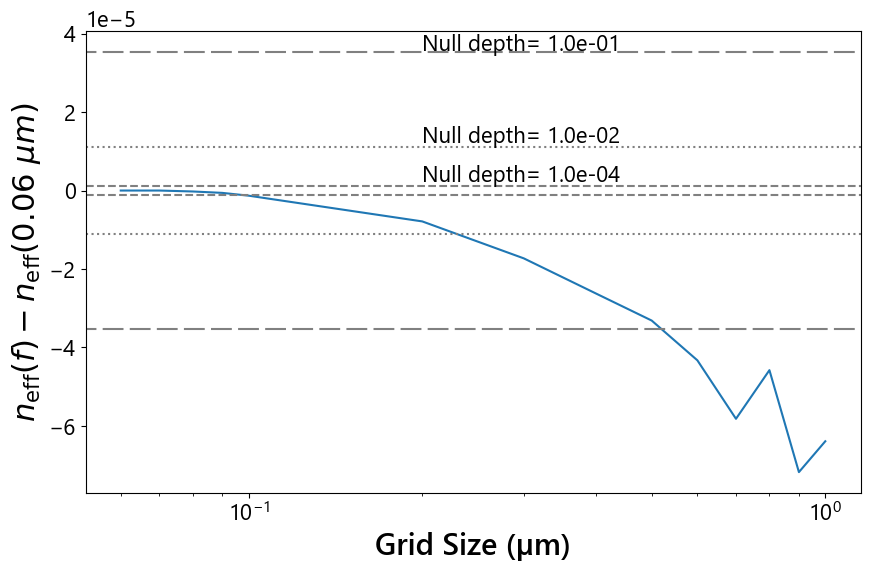

In [30]:
ind_grid_size = int(np.argwhere(np.isclose(grid_size_arr, 0.1)))
ind_grid_edge = int(np.argwhere(np.isclose(grid_edge_arr, 0.1)))

cmap = plt.get_cmap('RdYlBu_r')
norm = Normalize(vmin=min(wav_arr), vmax=max(wav_arr))
 
fig, ax = plt.subplots(figsize=(10, 6))
 
y = neff_cube[:, :, ind_grid_edge] - neff_cube[:, 0, ind_grid_edge][:, None]
 
for i, w in enumerate(wav_arr):
    ax.semilogx(grid_size_arr, y[i])#, color=cmap(norm(w)))
 
ntable = np.loadtxt(f'D:\\DATA\\SURF_2026\\ConvergenceTest\\Neff_tolerance.txt', delimiter=',', skiprows=1)
 
ax.axhline(ntable[0, 1], linestyle=(5, (10, 3)), color="grey")
ax.axhline(ntable[1, 1], linestyle="dotted", color="grey")
ax.axhline(ntable[3, 1], linestyle="dashed", color="grey")
 
ax.axhline(-ntable[0, 1], linestyle=(5, (10, 3)), color="grey")
ax.axhline(-ntable[1, 1], linestyle="dotted", color="grey")
ax.axhline(-ntable[3, 1], linestyle="dashed", color="grey")
 
ax.text(0.2, ntable[0, 1]*1.01, f"Null depth= {ntable[0, 0]:0.1e}", fontsize=16)
ax.text(0.2, ntable[1, 1]*1.1, f"Null depth= {ntable[1, 0]:0.1e}", fontsize=16)
ax.text(0.2, ntable[3, 1]*1.9, f"Null depth= {ntable[3, 0]:0.1e}", fontsize=16)
 
ax.set_xlabel("Grid Size (µm)")
ax.set_ylabel(r"$n_{\rm eff}(f) - n_{\rm eff}(0.06\ µm)$")
 
sm = cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])
# cbar = fig.colorbar(sm, ax=ax)
cbar.set_label('Wavelength (nm)', rotation=270, labelpad=25)
cbar.set_ticks(wav_arr)
 
plt.show()

# Simulated bend waveguide: PML width vs. volume

In [ ]:
# Define directories and files to work with
working_dir = "D:\\DATA\\ActivePIC\\SingleWaveguideConvergence\\"
save_dir = f"{working_dir}StraightWaveguide_simulatedBend_scan_PMLwidth_VolumeXY\\"
os.makedirs(save_dir, exist_ok=True)
filename_root = "StraightWaveguide_simulatedBend"
filename = f"{filename_root}.ind"

# Define parameter scan
PML_arr = np.arange(0, 2.1, 0.25)
volume_arr = np.arange(2, 8.1, 1)
wav_arr = np.linspace (1.45, 1.65, 5)
grid_size, grid_edge = 0.1, 0.1

for wav in tqdm(wav_arr, desc='Wavelength loop', position=0, leave=False): 
    print(f'Wavelength: {wav} microns')
    wav_str = f"{wav:0.3f}".replace(".", "p")
    for PML in tqdm(PML_arr, desc='PML width loop', position=0, leave=False):
        PML_str = f"{PML:0.3f}".replace(".", "p")
        for volume in tqdm(volume_arr, desc='Volume loop', position=0, leave=False):  
            volume_str = f"{volume:0.3f}".replace(".", "p")

            c = RSoftCircuit()
            c.read(working_dir+filename)
            c.set_symbol("free_space_wavelength", wav)
            c.set_symbol("Contrast", 1.02)
            c.set_symbol("Grid_x", grid_size)
            c.set_symbol("Grid_y", grid_size)
            c.set_symbol("Grid_z", grid_size)
            c.set_symbol("Grid_Edge", grid_edge)

            c.set_symbol("PML_width", PML)
            c.set_symbol("Volume_transverse", volume)


            c.write(working_dir+filename)
            
            command = ["femsim", "-min", filename, "mode_method=1", "mode_set=1", "idbpm_convergence_warning=0",
                    f"prefix={save_dir}/{filename_root}_Wav{wav_str}_PML{PML_str}_Volume{volume_str}", "wait=0"]

            print(f'Wavelength written: {rsoft_lib.read_symbol(working_dir+filename, "free_space_wavelength")}')
            print(f'PML width written: {rsoft_lib.read_symbol(working_dir+filename, "PML_width")}')
            print(f'Volume written: {rsoft_lib.read_symbol(working_dir+filename, "Volume_transverse")}')
            
            # Run the command
            result = subprocess.run(command, cwd=working_dir, capture_output=True, text=True)

            metadata_name = f'{save_dir}{filename_root}_Wav{wav_str}_PML{PML_str}_Volume{volume_str}.json'
            symbols = rsoft_lib.export_symbols(working_dir+filename, metadata_name)

            filename_nef = f'{save_dir}/{filename_root}_Wav{wav_str}_PML{PML_str}_Volume{volume_str}.nef'         
            sim = np.genfromtxt(filename_nef)
            neff = sim[1]
            print(f"n_eff: {neff}")

np.save(f"{save_dir}{filename_root}_Wav.npy", wav_arr)
np.save(f"{save_dir}{filename_root}_PML.npy", PML_arr)
np.save(f"{save_dir}{filename_root}_Volume.npy", volume_arr)

# Simulated bend waveguide: Generate $n_{\mathrm{eff}}$ table

In [18]:
# Define directories and files to work with
working_dir = "D:\\DATA\\ActivePIC\\SingleWaveguideConvergence\\"
save_dir = f"{working_dir}StraightWaveguide_simulatedBend_neff_table\\"
os.makedirs(save_dir, exist_ok=True)
filename_root = "StraightWaveguide_simulatedBend"
filename = f"{filename_root}.ind"

# Define parameter scan
grid_size = 0.05
grid_edge = 0.5
# wav_arr = np.arange(1.675, 1.81, 0.025)
# radius_arr = [300, 350, 400, 450, 500, 550, 600, 700, 800, 900, 1000, 1200, 1400, 1700, 2000, 2500, 3000, 4000, 5000, 7000, 10000, 15000, 25000]
wav_arr = [1.775, 1.80]
radius_arr = [800, 900]

for radius in tqdm(radius_arr, desc='Radius loop', position=0, leave=False):
    radius_str = f"{radius:0.3f}".replace(".", "p")
    for wav in tqdm(wav_arr, desc='Wavelength loop', position=0, leave=False): 
        print(f'Wavelength: {wav} microns')
        wav_str = f"{wav:0.3f}".replace(".", "p")
    
        c = RSoftCircuit()
        c.read(working_dir+filename)
        c.set_symbol("free_space_wavelength", wav)
        c.set_symbol("simulated_bend_radius", radius)
        c.set_symbol("width", 3.4)
        c.set_symbol("height", 3.4)
        c.set_symbol("Contrast", 1.02)
        c.set_symbol("Grid_x", grid_size)
        c.set_symbol("Grid_y", grid_size)
        c.set_symbol("Grid_z", grid_size)
        c.set_symbol("Grid_Edge", grid_edge)
        c.set_symbol("PML_width", 5)
        c.set_symbol("Volume_transverse", 3.4+10)
        c.write(working_dir+filename)
        
        command = ["femsim", "-min", filename, "mode_method=1", "mode_set=1", "idbpm_convergence_warning=0",
                f"prefix={save_dir}{filename_root}_Wav{wav_str}_Radius{radius_str}", "wait=0"]

        print(f'Wavelength written: {rsoft_lib.read_symbol(working_dir+filename, "free_space_wavelength")}')
        print(f'Radius written: {rsoft_lib.read_symbol(working_dir+filename, "simulated_bend_radius")}')
        
        # Run the command
        result = subprocess.run(command, cwd=working_dir, capture_output=True, text=True)

        metadata_name = f'{save_dir}{filename_root}_Wav{wav_str}_Radius{radius_str}.json'
        symbols = rsoft_lib.export_symbols(working_dir+filename, metadata_name)

        filename_nef = f'{save_dir}{filename_root}_Wav{wav_str}_Radius{radius_str}.nef'         
        sim = np.genfromtxt(filename_nef)
        neff = sim[1]
        print(f"n_eff: {neff}")

# wav_arr_previous = np.load(f"{save_dir}{filename_root}_Wav.npy")
# np.save(f"{save_dir}{filename_root}_Wav.npy", np.append(wav_arr_previous, wav_arr))
# np.save(f"{save_dir}{filename_root}_Radius.npy", radius_arr)

Wavelength loop:   0%|          | 0/2 [00:00<?, ?it/s]

Wavelength: 1.775 microns
Wavelength written: 1.775
Radius written: 800


Wavelength loop:  50%|█████     | 1/2 [11:42<11:42, 702.84s/it]

n_eff: [1.00000000e+00 1.45289946e+00 2.79782871e-05]
Wavelength: 1.8 microns
Wavelength written: 1.8
Radius written: 800


Radius loop:  50%|█████     | 1/2 [42:51<42:51, 2571.19s/it]    

n_eff: [1.00000000e+00 1.45231688e+00 3.47970272e-05]


Wavelength loop:   0%|          | 0/2 [00:00<?, ?it/s]

Wavelength: 1.775 microns
Wavelength written: 1.775
Radius written: 900


Wavelength loop:  50%|█████     | 1/2 [08:44<08:44, 524.57s/it]

n_eff: [1.00000000e+00 1.45281601e+00 1.42044764e-05]
Wavelength: 1.8 microns
Wavelength written: 1.8
Radius written: 900


n_eff: [1.00000000e+00 1.45222998e+00 1.82195490e-05]


In [19]:
import pandas as pd

# --------------------------------------------------------------------- #
# Config -- must match the scan script
# --------------------------------------------------------------------- #
working_dir = "D:\\DATA\\ActivePIC\\SingleWaveguideConvergence\\"
save_dir = f"{working_dir}StraightWaveguide_simulatedBend_neff_table\\"
filename_root = "StraightWaveguide_simulatedBend"

# --------------------------------------------------------------------- #
# Load the swept parameter arrays
# --------------------------------------------------------------------- #
wav_arr = np.load(f"{save_dir}{filename_root}_Wav.npy")
radius_arr = np.load(f"{save_dir}{filename_root}_Radius.npy")

n_wav, n_radius = len(wav_arr), len(radius_arr)

# --------------------------------------------------------------------- #
# Load n_eff (real + imaginary parts) for every (radius, wavelength) pair.
# Missing/unreadable files become NaN rather than crashing the whole load
# -- given how many runs in this conversation have failed partway through
# a sweep, this is not a hypothetical concern.
# --------------------------------------------------------------------- #
neff_real = np.full((n_radius, n_wav), np.nan)
neff_imag = np.full((n_radius, n_wav), np.nan)

n_missing = 0
for ir, radius in enumerate(radius_arr):
    radius_str = f"{radius:0.3f}".replace(".", "p")
    for il, wav in enumerate(wav_arr):
        wav_str = f"{wav:0.3f}".replace(".", "p")
        fn = f'{save_dir}{filename_root}_Wav{wav_str}_Radius{radius_str}.mon'
        mon = rsoft_lib.read_monitor(fn)
        test = mon.z[np.argsort(mon.values[:,0])[::-1]][:2]
        peaks = []
        for t in test[::-1]:
            fn = f"{save_dir}{filename_root}_Wav{wav_str}_Radius{radius_str}_ex.m{t:02.0f}"
            ex = np.genfromtxt(fn, skip_header=4)
            amp = ex[:, 0::2] 
            peaks.append(np.max(amp))
        row = int(test[np.argmax(peaks)])
        fn = f'{save_dir}{filename_root}_Wav{wav_str}_Radius{radius_str}.nef'
        try:
            sim = np.genfromtxt(fn)
            neff_real[ir, il] = sim[row, 1]
            neff_imag[ir, il] = sim[row, 2] if sim.size > 2 else 0.0
        except (FileNotFoundError, IndexError, OSError):
            n_missing += 1

if n_missing:
    print(f"Warning: {n_missing} of {n_radius * n_wav} (radius, wavelength) "
          f"combinations had no readable .nef file and are NaN in the table.")

# --------------------------------------------------------------------- #
# Wide-format tables: rows = width, columns = wavelength
# --------------------------------------------------------------------- #
wav_cols = [f"{w:.3f}" for w in wav_arr]
radius_index = [f"{r:.3f}" for r in radius_arr]

df_neff_real = pd.DataFrame(neff_real, index=radius_index, columns=wav_cols)
df_neff_real.index.name = "radius (um)"
df_neff_real.columns.name = "wavelength (um)"

df_neff_imag = pd.DataFrame(neff_imag, index=radius_index, columns=wav_cols)
df_neff_imag.index.name = "radius (um)"
df_neff_imag.columns.name = "wavelength (um)"

df_neff_real.to_csv(f"{save_dir}{filename_root}_neff_real_table.csv")
df_neff_imag.to_csv(f"{save_dir}{filename_root}_neff_imag_table.csv")

# --------------------------------------------------------------------- #
# Long-format table: one row per (wavelength, width) pair, with columns
# in the order (wavelength, width, neff) -- this is usually the more
# convenient format for plotting/filtering than the wide pivoted table.
# --------------------------------------------------------------------- #
radius_grid, wav_grid = np.meshgrid(radius_arr, wav_arr, indexing="ij")
df_long = pd.DataFrame({
    "wavelength": wav_grid.ravel(),
    "radius": radius_grid.ravel(),
    "neff_real": neff_real.ravel(),
    "neff_imag": neff_imag.ravel(),
})
df_long.to_csv(f"{save_dir}{filename_root}_neff_long.csv", index=False)

print(f"\nWrote:")
print(f"  {save_dir}{filename_root}_neff_real_table.csv  (wide, {n_radius}x{n_wav})")
print(f"  {save_dir}{filename_root}_neff_imag_table.csv  (wide, {n_radius}x{n_wav})")
print(f"  {save_dir}{filename_root}_neff_long.csv         (long, {n_radius*n_wav} rows, "
      f"columns: wavelength, radius, neff, neff_imag)")

print("\nLong-format table preview:")
print(df_long.round(5).head(10))


Wrote:
  D:\DATA\ActivePIC\SingleWaveguideConvergence\StraightWaveguide_simulatedBend_neff_table\StraightWaveguide_simulatedBend_neff_real_table.csv  (wide, 23x15)
  D:\DATA\ActivePIC\SingleWaveguideConvergence\StraightWaveguide_simulatedBend_neff_table\StraightWaveguide_simulatedBend_neff_imag_table.csv  (wide, 23x15)
  D:\DATA\ActivePIC\SingleWaveguideConvergence\StraightWaveguide_simulatedBend_neff_table\StraightWaveguide_simulatedBend_neff_long.csv         (long, 345 rows, columns: wavelength, radius, neff, neff_imag)

Long-format table preview:
   wavelength  radius  neff_real  neff_imag
0       1.450     300    1.46206    0.00028
1       1.475     300    1.46150    0.00032
2       1.500     300    1.46093    0.00035
3       1.525     300    1.46037    0.00040
4       1.550     300    1.45980    0.00044
5       1.575     300    1.45924    0.00049
6       1.600     300    1.45867    0.00054
7       1.625     300    1.45810    0.00059
8       1.650     300    1.45753    0.00064
9  

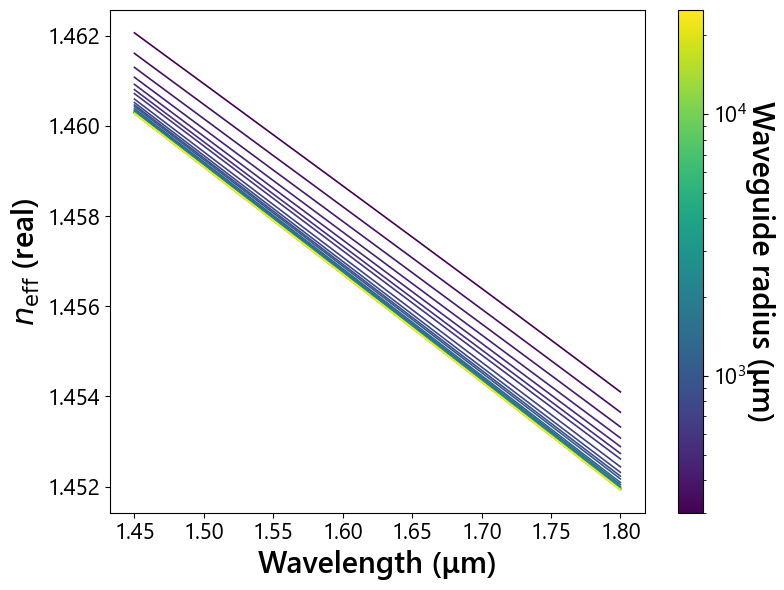

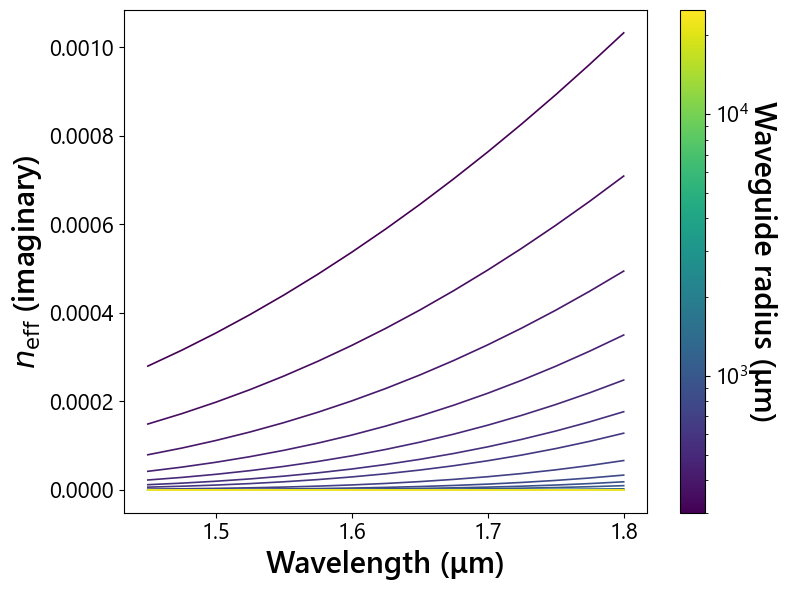

In [39]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.cm as cm
from matplotlib.colors import Normalize

# --------------------------------------------------------------------- #
# Config -- must match the scan / compile-table scripts
# --------------------------------------------------------------------- #
working_dir = "D:\\DATA\\ActivePIC\\SingleWaveguideConvergence\\"
save_dir = f"{working_dir}StraightWaveguide_simulatedBend_neff_table\\"
filename_root = "StraightWaveguide_simulatedBend"

# --------------------------------------------------------------------- #
# Load the long-format table produced by compile_neff_table.py
# --------------------------------------------------------------------- #
df = pd.read_csv(f"{save_dir}{filename_root}_neff_long_fullWavelengthRange.csv")

radii = np.sort(df["radius"].unique())

# --------------------------------------------------------------------- #
# Colormap setup: map width -> color continuously
# --------------------------------------------------------------------- #
from matplotlib.colors import LogNorm

cmap = plt.get_cmap("viridis")
norm = LogNorm(vmin=radii.min(), vmax=radii.max())
sm = cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])  # required for older matplotlib versions to allow colorbar() without data

fig, ax = plt.subplots(figsize=(8, 6))

for radius in radii:
    sub = df[df["radius"] == radius].sort_values("wavelength")
    ax.plot(sub["wavelength"], sub["neff_real"], color=cmap(norm(radius)), linewidth=1.2)

cbar = fig.colorbar(sm, ax=ax)
cbar.set_label("Waveguide radius (\u03bcm)", rotation=270, labelpad=20)

ax.set_xlabel("Wavelength (\u03bcm)")
ax.set_ylabel("$n_\mathrm{eff}$ (real)")

fig.tight_layout()
fig.savefig(f"{save_dir}{filename_root}_neff_vs_wavelength_by_radius_real.png", dpi=150)
plt.show()

fig, ax = plt.subplots(figsize=(8, 6))

for radius in radii:
    sub = df[df["radius"] == radius].sort_values("wavelength")
    ax.plot(sub["wavelength"], sub["neff_imag"], color=cmap(norm(radius)), linewidth=1.2)
    if np.sum(sub['neff_imag'] > 0.002):
        print(radius)
        print(sub["wavelength"][sub['neff_imag'] > 0.002])

cbar = fig.colorbar(sm, ax=ax)
cbar.set_label("Waveguide radius (\u03bcm)", rotation=270, labelpad=20)

ax.set_xlabel("Wavelength (\u03bcm)")
ax.set_ylabel("$n_\mathrm{eff}$ (imaginary)")

fig.tight_layout()
fig.savefig(f"{save_dir}{filename_root}_neff_vs_wavelength_by_radius_imag.png", dpi=150)
plt.show()

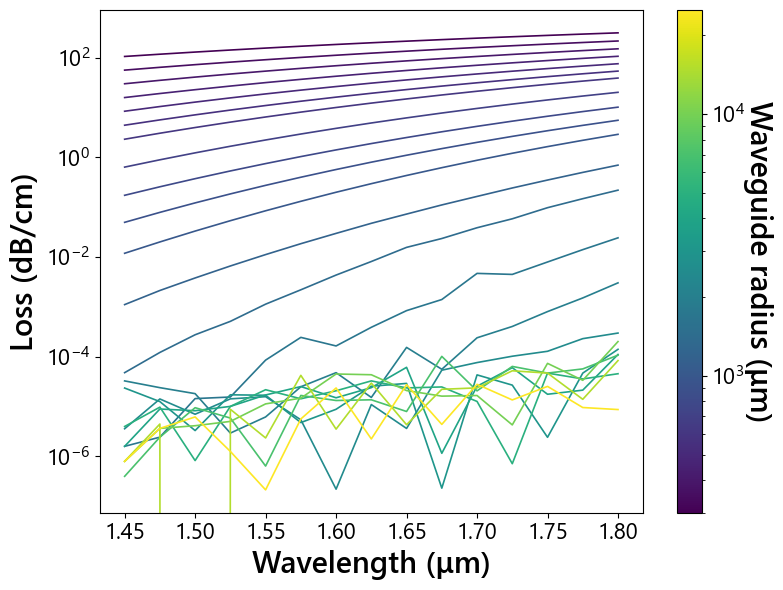

In [46]:
import numpy as np
import pandas as pd

df = pd.read_csv(f"{save_dir}{filename_root}_neff_long_fullWavelengthRange.csv")

lam_um = df["wavelength"]
n_im = df["neff_imag"].abs()            # sign convention varies; loss uses |n''|

alpha_per_um = 4 * np.pi * n_im / lam_um               # power attenuation, 1/um
df["loss_dB_per_cm"] = 10*np.log10(np.exp(alpha_per_um * 1e4))

table_cm = (df[["radius", "wavelength", "loss_dB_per_cm"]]
            .sort_values(["radius", "wavelength"])
            .reset_index(drop=True))

table_cm.to_csv(f"{save_dir}{filename_root}_bendloss_dB_per_cm.csv", index=False)

fig, ax = plt.subplots(figsize=(8, 6))

for radius in radii:
    sub = df[df["radius"] == radius].sort_values("wavelength")
    ax.semilogy(sub["wavelength"], sub["loss_dB_per_cm"], color=cmap(norm(radius)), linewidth=1.2)

cbar = fig.colorbar(sm, ax=ax)
cbar.set_label("Waveguide radius (\u03bcm)", rotation=270, labelpad=20)


ax.set_xlabel("Wavelength (\u03bcm)")
ax.set_ylabel("Loss (dB/cm)")

fig.tight_layout()
fig.savefig(f"{save_dir}{filename_root}_neff_vs_wavelength_by_radius_loss.png", dpi=150)
plt.show()